# QBUS6810 M4：新版数据 Boosting、MSE调参与三情景WAE

按组员 **train(2) / validation(2) / test(2)** 的成交划分重新训练。训练：2023-01至2024-06，共54,853笔；验证：2024-07至12，共18,132笔；2025测试仅在最终冻结后启用。这里的实际输出为重新训练结果，未复用旧数据的预测。

**Colab运行**：先运行安装单元，上传本次train(2).csv和validation(2).csv（可改为train.csv/validation.csv），再顺序运行。所有函数均在本Notebook中，无需任何外部.py、旧manifest或旧结果文件；CPU即可。数据默认SHA锁定本次版本，防止选中旧文件。24个LightGBM配置加27个对照配置，运行时间依CPU而异。结果表、模型、预测和图自动导出，最后可下载ZIP。

**预先确定的规则**：每个模型族在已测试且收敛的配置中按原始美元尺度验证MSE最小选冠军，再按三种WAE比较冠军；主情景固定为高估:低估=2:1。1:1和1:2用于敏感性分析，所有情景使用同一组逐笔预测。无0.5%容差。有限搜索不能保证数学上的全局最优。

**M4责任范围**：Boosting实现、3f模型选取、4c权重敏感性、4d试点判断、5d假设案例、7d个人反思提示。4b的真实镇区/物业类型分析需上游交付原始ID与分组字段，不能把TE值当作镇区代码。

**本次修正**：上游分别drop_first导致验证集10月全零，误与训练集1月混淆。本Notebook在已确认的2024H2范围内修复这3,087行的month_10。原有面积/经度全零问题已修复。已审阅上游OOF目标编码函数，保留13列TE；由于缺少原始物业、销售、工程规则文件，不声称独立复现整个上游。


**已验证输出**：51个实际训练配置、8类MSE冠军、9张内嵌图；所有逐笔预测的MSE与三种WAE已复算。主情景选LightGBM；1:2敏感性下随机森林排名更高。读取本Notebook即可看到图与表，重新运行会重新训练完整实验。

## 1. 运行环境

In [1]:
# Colab使用方法：先运行本单元安装两个课件依赖；无需GPU、cartopy或地图下载。
import importlib.util, importlib.metadata, subprocess, sys
for package,version in [('lightgbm','4.6.0'),('optuna','4.5.0'),('tabulate','0.9.0')]:
    try: installed=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: installed=None
    if installed!=version:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',f'{package}=={version}'])


## 2. 预先锁定实验规则与文件版本
MSE重视大额价格误差，适合本次用户指定的数值优化目标；WAE反映方向优先级，是后续业务选择目标。二者不应混称。第十周课件中的LightGBM、Optuna、早停、学习曲线思路被保留，课件随机切分改为组员已给定的时间验证。

In [2]:
import os
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']: os.environ[key]='2'
import json,hashlib,time,platform,zipfile,copy,importlib.metadata,warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib,sklearn,lightgbm as lgb,optuna
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,SplineTransformer
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display,Markdown
SEED=6810;N_THREADS=2
N_LGB_TRIALS=24
MAX_BOOST_ROUNDS=1400;EARLY_STOPPING_ROUNDS=100
SCENARIOS={'equal_1_1':(1.,1.),'over_2_under_1':(2.,1.),'under_2_over_1':(1.,2.)}
PRIMARY_SCENARIO='over_2_under_1' # 必须在搜索前确定，不能看排名后改。
RUN_FINAL_TEST=False
DOWNLOAD_OUTPUT_ZIP=False
# 本次明确指定数据版本，防止同目录旧train.csv被误读。不读取test内容进行调参。
EXPECTED_SHA={'train':'9968adbaa619663d54332234c8537e912530c4c6db79f82aaf155e39b56db6e8',
'validation':'656ff297a2ac2bfcf9644e7505350b2a3b3769804f1c240a00180842d422eb5e',
'test':'1a37862b7443d5529f6771737fe0efcd10f95833f7165a42e9024e7a4efec24a'}
EXPECTED_ROWS={'train':54853,'validation':18132,'test':36322}
DATA_DIR=Path('data/split') # 可改为已挂载的Google Drive目录。
def file_sha(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
 return h.hexdigest()
def write_json(path,obj):Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
def aliases(name):
 stem=Path(name).stem
 return [f'{stem}(2).csv',f'{stem} (2).csv',name]
def matching_file(root,name):
 for alias in aliases(name):
  p=root/alias
  if p.is_file() and file_sha(p)==EXPECTED_SHA[Path(name).stem]:return p
 return None
roots=[DATA_DIR,Path('upload'),Path('/content'),Path('.')]
DATA_DIR=next((r for r in roots if all(matching_file(r,n) for n in ['train.csv','validation.csv'])),DATA_DIR)
if not all(matching_file(DATA_DIR,n) for n in ['train.csv','validation.csv']):
 try:from google.colab import files
 except ImportError:raise FileNotFoundError('请指定本次新版train/validation CSV所在目录。')
 print('请上传本次train(2).csv、validation(2).csv；也支持改名为train.csv、validation.csv。')
 files.upload();DATA_DIR=Path('.')
def resolve_input(name):
 p=matching_file(DATA_DIR,name)
 if p is None:raise ValueError(f'{name}不存在或SHA与本次数据不符。不要使用旧manifest或旧CSV。')
 return p
INPUT_FILES={n:resolve_input(n) for n in ['train.csv','validation.csv']}
OUT=Path('outputs_m4_updated')/time.strftime('run_%Y%m%d_%H%M%S');OUT.mkdir(parents=True,exist_ok=False)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns',22);pd.set_option('display.width',180)
def show_saved(name):
 from IPython.display import Image
 display(Image(filename=str(OUT/name)))
CONFIG=dict(seed=SEED,N_LGB_TRIALS=N_LGB_TRIALS,MAX_BOOST_ROUNDS=MAX_BOOST_ROUNDS,
 EARLY_STOPPING_ROUNDS=EARLY_STOPPING_ROUNDS,PRIMARY_SCENARIO=PRIMARY_SCENARIO,scenarios=SCENARIOS,
 input_sha={n:file_sha(p) for n,p in INPUT_FILES.items()},expected_test_sha=EXPECTED_SHA['test'],
 selection='within family MSE; between family MSE champions WAE',test_read=False,
 versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','lightgbm','optuna','matplotlib']},python=platform.python_version())
write_json(OUT/'run_manifest.json',CONFIG)
print('新版输入SHA校验通过：',INPUT_FILES);print('输出：',OUT)


新版输入SHA校验通过： {'train.csv': PosixPath('upload/train(2).csv'), 'validation.csv': PosixPath('upload/validation(2).csv')}
输出： outputs_m4_updated/run_20261026_160537


## 3. 输入清洗复核与泄漏防范（在EDA与训练前）
这是已经清洗/标准化/分箱的快照，不能把负的标准化面积当作非法物理面积再删。检查字段、缺失/无限、正价格、log目标一致性、月份和时间边界，删除目标与训练恒定列；输出逐列审计。加工后相同行可能是不同成交，缺少交易ID时不武断去重。

上游cell110对训练进行5折OOF目标编码，验证/测试仅用训练拟合映射，故保留TE。内部OOF不是外层随机验证；它防止本行直接使用自身目标，但同一物业多次交易可能进入不同OOF折，尚不能独立核验其影响。上游训练期拟合填补、裁剪、Yeo–Johnson、缩放及稀有类别映射的代码已审阅，仍需原始文件才能完整复现。销售月在估值时须已知；若业务是提前预测未来成交，则另需定义预测时点与可用特征。

In [3]:
# 不重划分、不重排成交记录；仅修正已核查的月份编码并删除目标与训练恒定列。
train_df=pd.read_csv(INPUT_FILES['train.csv']);valid_df=pd.read_csv(INPUT_FILES['validation.csv'])
assert train_df.columns.is_unique and train_df.columns.tolist()==valid_df.columns.tolist()
assert train_df.shape==(54853,211) and valid_df.shape==(18132,211)
for frame in [train_df,valid_df]:
 assert frame.select_dtypes(exclude='number').empty
 assert np.isfinite(frame.to_numpy(dtype=float)).all(), '预处理快照出现缺失或无穷，需要回查上游。'
 assert frame.sale_price.gt(0).all()
 np.testing.assert_allclose(frame.log_sale_price,np.log1p(frame.sale_price),rtol=1e-12)
# 上游get_dummies在每份数据独立drop_first：验证集因字符串排序丢弃10月，而训练集丢弃1月。
# 固定此版SHA与源代码后，2024H2内全零月份行可唯一恢复为10月；不从价格推断月份。
month_cols=[f'month_{m}' for m in range(2,13)]
assert all(c in train_df for c in month_cols)
for frame in [train_df,valid_df]:
 assert frame[month_cols].isin([0,1]).all().all()
 assert frame[month_cols].sum(axis=1).le(1).all()
zero_valid=valid_df[month_cols].sum(axis=1).eq(0)
assert valid_df.month_10.eq(0).all() and int(zero_valid.sum())==3087
valid_df.loc[zero_valid,'month_10']=1
assert valid_df[month_cols].sum(axis=1).eq(1).all()
def decode_months(frame):
 arr=frame[month_cols].to_numpy();return np.where(arr.sum(axis=1)==0,1,np.array(list(range(2,13)))[arr.argmax(axis=1)])
train_months=decode_months(train_df);valid_months=decode_months(valid_df)
assert set(valid_months)==set(range(7,13))
# house_age的生成源为未标准化的char_yrblt；可独立恢复估值年用于审计，不新增为模型特征。
train_years=np.rint(train_df.char_yrblt+train_df.house_age).astype(int)
valid_years=np.rint(valid_df.char_yrblt+valid_df.house_age).astype(int)
assert np.all((train_years==2023)|((train_years==2024)&(train_months<=6)))
assert np.all(valid_years==2024)
# 时间元数据仅用于图和审计，不加入X。
train_df['sale_year']=train_years;train_df['sale_month']=train_months
valid_df['sale_year']=valid_years;valid_df['sale_month']=valid_months
forbidden=['sale_price','log_sale_price','sale_year','sale_month']
te_cols=[c for c in train_df if c.endswith('_te')]
# 已审阅assignment_6810.ipynb cell110：训练5折OOF，验证/测试映射只fit全训练标签。
# 保留TE；这不是随机重划分外层验证集。未取得原始数据，不能声称独立复现整个上游。
constant=[c for c in train_df if c not in forbidden and train_df[c].nunique(dropna=False)<=1]
FEATURES=[c for c in train_df if c not in forbidden+constant]
assert not {'sale_price','log_sale_price','property_id','transaction_id'}&set(FEATURES)
X_train=train_df[FEATURES].copy();X_valid=valid_df[FEATURES].copy()
y_train=train_df.sale_price.to_numpy(dtype=float);y_valid=valid_df.sale_price.to_numpy(dtype=float)
VALID_IDS=np.array([f'validation:{i:06d}' for i in range(len(valid_df))]);validation_sha=EXPECTED_SHA['validation']
validation_manifest=pd.DataFrame({'row_id':VALID_IDS,'validation_sha256':validation_sha,'sale_year':valid_years,'sale_month':valid_months})
validation_manifest.to_csv(OUT/'validation_row_manifest.csv',index=False)
pd.DataFrame([{'feature':c,'decision':'target_or_metadata' if c in forbidden else 'training_constant' if c in constant else 'retained',
 'train_unique':train_df[c].nunique(),'train_missing':train_df[c].isna().sum()} for c in train_df]).to_csv(OUT/'feature_audit.csv',index=False)
write_json(OUT/'feature_columns.json',FEATURES)
audit=dict(provided_columns=211,retained_features=len(FEATURES),targets_excluded=['sale_price','log_sale_price'],constant=constant,
 TE_columns=te_cols,TE_source_reviewed=True,upstream_reproduced=False,month10_repaired_rows=int(zero_valid.sum()),
 property_ID_available=False,source_notebook='assignment_6810.ipynb',test_read=False)
write_json(OUT/'input_audit.json',audit)
period_counts=pd.concat([train_df[['sale_year','sale_month']].assign(split='train'),valid_df[['sale_year','sale_month']].assign(split='validation')]).groupby(['split','sale_year','sale_month']).size().rename('n').reset_index()
period_counts.to_csv(OUT/'split_month_counts.csv',index=False)
print('输入211列 = 2个目标 + 209个已编码预测列；本次保留',len(FEATURES),'列，其中TE',len(te_cols),'列。')
print('修复验证集10月',zero_valid.sum(),'行；训练/验证时间边界复核通过。')
print('面积/土地/经度unique：',train_df[['char_bldg_sf','char_land_sf','loc_longitude']].nunique().to_dict())
print('矩阵重复行：',int(train_df.duplicated(subset=FEATURES+['sale_price']).sum()),int(valid_df.duplicated(subset=FEATURES+['sale_price']).sum()),'（不当作重复交易删除）')
display(period_counts)


输入211列 = 2个目标 + 209个已编码预测列；本次保留 209 列，其中TE 13 列。
修复验证集10月 3087 行；训练/验证时间边界复核通过。
面积/土地/经度unique： {'char_bldg_sf': 4112, 'char_land_sf': 9880, 'loc_longitude': 50625}
矩阵重复行： 0 0 （不当作重复交易删除）


split,sale_year,sale_month,n
train,2023,1,1973
train,2023,2,2274
train,2023,3,3305
train,2023,4,3217
train,2023,5,3847
train,2023,6,4147
train,2023,7,3529
train,2023,8,3682
train,2023,9,3149
train,2023,10,3101


## 4. 轻量EDA与均值基线
主基线为**训练成交的原始美元售价算术均值**，不是log售价均值的反变换，不是训练+验证+测试全体均值。均值最小化训练常数预测的MSE，是合理的简单参照。1:1绝对误差的最优常数是中位数，2:1是1/3分位数，1:2是2/3分位数；它们只作补充，不替换题目指定均值基线。所有基准仅fit训练价格。

train,validation
54853.00,18132.00
418490.00,449525.20
391202.77,436738.43
10639.00,11700.00
121500.00,136000.00
325000.00,349000.00
775000.00,820000.00
2050000.00,2167560.00
12500000.00,15250000.00


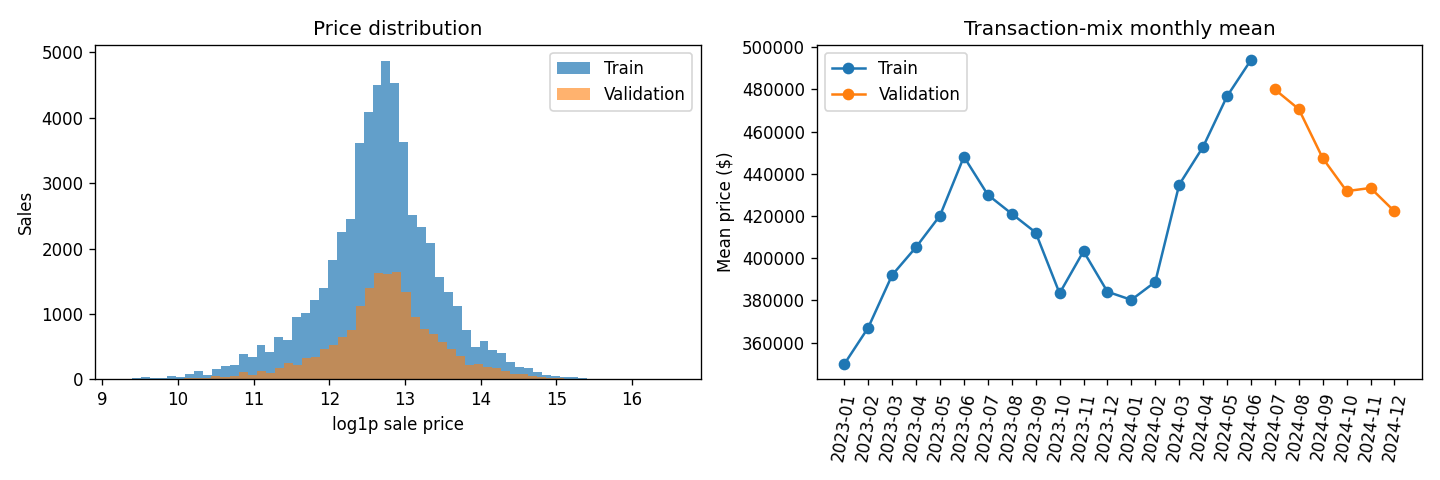

In [4]:
# 价格分布只展示训练/验证；验证分布不决定清洗阈值。
summary=pd.DataFrame({'train':pd.Series(y_train).describe(percentiles=[.1,.5,.9,.99]),'validation':pd.Series(y_valid).describe(percentiles=[.1,.5,.9,.99])})
display(summary.round(2));summary.to_csv(OUT/'price_summary.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(np.log1p(y_train),bins=60,alpha=.7,label='Train');axes[0].hist(np.log1p(y_valid),bins=60,alpha=.6,label='Validation');axes[0].set(xlabel='log1p sale price',ylabel='Sales',title='Price distribution');axes[0].legend()
for label,frame in [('Train',train_df),('Validation',valid_df)]:
 m=frame.groupby(['sale_year','sale_month']).sale_price.mean();axes[1].plot([f'{y}-{m:02}' for y,m in m.index],m.values,'o-',label=label)
axes[1].tick_params(axis='x',rotation=80);axes[1].set(ylabel='Mean price ($)',title='Transaction-mix monthly mean');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'00_price_EDA.png',dpi=120);plt.close(fig);show_saved('00_price_EDA.png')


In [5]:
def nonnegative_prediction(pred):
    pred=np.asarray(pred,dtype=float)
    if not np.isfinite(pred).all():raise ValueError('预测存在NaN/Inf，不能默默填成0。')
    return np.maximum(pred,0.)

def to_dollars(pred,target):
    # 不按验证/测试价格分位数截断，保留尾部误差。
    p=np.expm1(pred) if target=='log1p' else np.asarray(pred)
    return nonnegative_prediction(p)

def weighted_absolute_error(y,pred,weights):
    e=np.asarray(pred)-np.asarray(y) # 正数高估，负数低估。
    return float(np.mean(np.abs(e)*np.where(e>0,weights[0],weights[1])))

def score_predictions(y,pred):
    y=np.asarray(y);pred=nonnegative_prediction(pred);e=pred-y
    r=dict(n=len(y),MSE=float(mean_squared_error(y,pred)),RMSE=float(np.sqrt(mean_squared_error(y,pred))),
        MAE=float(mean_absolute_error(y,pred)),R2=float(r2_score(y,pred)),mean_signed_error=float(e.mean()),
        overvaluation_rate=float(np.mean(e>0)),median_APE=float(np.median(np.abs(e)/y)),
        within_20pct=float(np.mean(np.abs(e)/y<=.2)))
    for name,w in SCENARIOS.items():r['WAE_'+name]=weighted_absolute_error(y,pred,w)
    # O/U都除以全部交易数，便于解释方向权重变化。
    r.update(over_error_contribution=float(np.maximum(e,0).mean()),
             under_error_contribution=float(np.maximum(-e,0).mean()))
    return r

assert np.isclose(weighted_absolute_error([100,100,100],[120,70,100],(2,1)),70/3)
assert np.isclose(weighted_absolute_error([100,100],[120,70],(1,1)),25)
candidate_records=[];candidate_specs={};validation_predictions={};family_best_models={};family_best_mse={}
lgb_histories={}

def register_candidate(family,model,params,target,pred,train_pred,seconds,phase,eligible=True):
    cid=f'C{len(candidate_records)+1:03d}'
    pred=nonnegative_prediction(pred);m=score_predictions(y_valid,pred)
    row=dict(candidate_id=cid,family=family,params=json.dumps(params,sort_keys=True),target=target,
        phase=phase,input_features=len(FEATURES),fit_seconds=seconds,eligible_for_selection=bool(eligible),
        train_MSE=float(mean_squared_error(y_train,nonnegative_prediction(train_pred))),**m)
    row['validation_train_MSE_ratio']=row['MSE']/max(row['train_MSE'],1e-12)
    candidate_records.append(row);validation_predictions[cid]=pred.copy()
    candidate_specs[cid]=dict(family=family,params=copy.deepcopy(params),target=target,phase=phase)
    if eligible and m['MSE']<family_best_mse.get(family,np.inf):
        family_best_mse[family]=m['MSE'];family_best_models[family]=(cid,model)
    pd.DataFrame(candidate_records).to_csv(OUT/'all_candidates_validation.csv',index=False)
    print(f"{cid} {family:14s} {target:6s}: MSE={m['MSE']:,.0f}, RMSE=${m['RMSE']:,.0f}, MAE=${m['MAE']:,.0f}",flush=True)
    return cid

# 三条常数基准均只使用训练售价；主报告默认Mean，其他两条提供补充背景。
baseline_values={'Mean baseline':float(y_train.mean()),'Median baseline':float(np.median(y_train)),
                 'Quantile1/3 baseline':float(np.quantile(y_train,1/3)),
                 'Quantile2/3 baseline':float(np.quantile(y_train,2/3))}
baseline_scores=pd.DataFrame([dict(model=name,**score_predictions(y_valid,np.repeat(value,len(y_valid))))
    for name,value in baseline_values.items()])
baseline_scores.to_csv(OUT/'baselines_validation.csv',index=False)
display(baseline_scores.round(3))


model,n,MSE,RMSE,MAE,R2,mean_signed_error,overvaluation_rate,median_APE,within_20pct,WAE_equal_1_1,WAE_over_2_under_1,WAE_under_2_over_1,over_error_contribution,under_error_contribution
Mean baseline,18132,1.916931e+11,437827.728,238599.618,-0.005,-31035.206,0.639,0.423,0.262,238599.618,342381.823,373417.029,103782.206,134817.412
Median baseline,18132,2.062365e+11,454132.647,228915.964,-0.081,-124525.202,0.445,0.359,0.300,228915.964,281111.346,405636.547,52195.381,176720.583
Quantile1/3 baseline,18132,2.289600e+11,478497.690,248117.924,-0.200,-195525.202,0.283,0.409,0.224,248117.924,274414.285,469939.487,26296.361,221821.563
Quantile2/3 baseline,18132,1.922922e+11,438511.319,236315.633,-0.008,-39525.202,0.626,0.414,0.265,236315.633,334710.849,374236.051,98395.216,137920.417


## 5. Boosting：LightGBM固定预算搜索
逐次加树拟合残差/负梯度，并用学习率收缩。搜索深度、叶数、叶最小样本、行列采样和L1/L2；固定种子、CPU线程和24次预算。叶数受深度约束，以避免不必要复杂度。最多1400轮，验证美元MSE连续100轮未改善则停止；取最佳轮数。

同时搜索raw价格与log1p价格训练目标；log配置在每轮先expm1还原美元，再用美元MSE早停和调参。log损失与美元损失不同，log模型不保证在美元MSE或均值预测上更好。所有预测统一下限0，无验证分位数截尾。最佳曲线加粗红色，每条细线是独立配置，绝不是同一个模型中途改变参数。

In [6]:
# 参考课件：LightGBM默认对照→Optuna搜索→早停→学习曲线。
# 与课件不同：保留给定时间切分，不随机5折；log目标也以美元MSE早停/选优。
def lightgbm_model(params,rounds=MAX_BOOST_ROUNDS):
    return lgb.LGBMRegressor(objective='regression',metric='None',n_estimators=rounds,
        random_state=SEED,n_jobs=N_THREADS,verbosity=-1,deterministic=True,force_col_wise=True,**params)

def fit_lgb_candidate(params,target):
    start=time.time();model=lightgbm_model(params);history={}
    yt=np.log1p(y_train) if target=='log1p' else y_train
    yv=np.log1p(y_valid) if target=='log1p' else y_valid
    def dollar_mse(y_true,pred):
        actual=np.expm1(y_true) if target=='log1p' else y_true
        prediction=to_dollars(pred,target)
        return 'dollar_MSE',float(mean_squared_error(actual,prediction)),False
    model.fit(X_train,yt,eval_set=[(X_train,yt),(X_valid,yv)],eval_names=['training','validation'],
        eval_metric=dollar_mse,callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS,first_metric_only=True,verbose=False),
        lgb.record_evaluation(history),lgb.log_evaluation(0)])
    rounds=int(model.best_iteration_ or MAX_BOOST_ROUNDS)
    pred=to_dollars(model.predict(X_valid,num_iteration=rounds),target)
    tp=to_dollars(model.predict(X_train,num_iteration=rounds),target)
    cid=register_candidate('LightGBM',model,{**params,'n_estimators':rounds},target,pred,tp,time.time()-start,'optuna_MSE')
    lgb_histories[cid]=history
    return cid,rounds

def lgb_objective(trial):
    target=trial.suggest_categorical('target',['raw','log1p'])
    depth=trial.suggest_categorical('max_depth',[4,6,8,-1])
    leaves=trial.suggest_int('num_leaves',8,48)
    if depth>0:leaves=min(leaves,2**depth)
    params=dict(max_depth=depth,num_leaves=leaves,
        learning_rate=trial.suggest_float('learning_rate',.025,.15,log=True),
        min_child_samples=trial.suggest_int('min_child_samples',30,180),
        subsample=trial.suggest_float('subsample',.7,1.),subsample_freq=1,
        colsample_bytree=trial.suggest_float('colsample_bytree',.65,1.),
        reg_alpha=trial.suggest_float('reg_alpha',1e-5,10.,log=True),
        reg_lambda=trial.suggest_float('reg_lambda',.01,100.,log=True))
    cid,rounds=fit_lgb_candidate(params,target)
    trial.set_user_attr('candidate_id',cid);trial.set_user_attr('best_iteration',rounds)
    # 返回的是美元²，不是log MSE；WAE不参与此次调参。
    return candidate_records[-1]['MSE']

write_json(OUT/'lightgbm_search_plan.json',dict(n_trials=N_LGB_TRIALS,max_rounds=MAX_BOOST_ROUNDS,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,objective='original-dollar validation MSE',
    random_folds=False,log_target_scored_after_inverse_transform=True))
study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=SEED,n_startup_trials=8))
# 第一组raw、第二组log使用相同的基础结构，随后才自适应搜索。
base=dict(max_depth=6,num_leaves=31,learning_rate=.05,min_child_samples=60,
          subsample=.9,colsample_bytree=.9,reg_alpha=.01,reg_lambda=1.)
study.enqueue_trial(dict(target='raw',**base));study.enqueue_trial(dict(target='log1p',**base))
study.optimize(lgb_objective,n_trials=N_LGB_TRIALS,n_jobs=1,show_progress_bar=False)
study.trials_dataframe().to_csv(OUT/'lightgbm_optuna_trials.csv',index=False)
write_json(OUT/'lightgbm_evaluation_histories.json',lgb_histories)
print('LightGBM最低验证MSE：',study.best_value,'；配置：',study.best_trial.user_attrs)
if all(r.get('best_iteration',0)>=MAX_BOOST_ROUNDS for r in [t.user_attrs for t in study.trials]):
    print('提醒：所有试验都达到轮数上限；有限预算可能不足，但不自动根据测试集扩展搜索。')


C001 LightGBM       raw   : MSE=45,066,789,100, RMSE=$212,289, MAE=$100,023
C002 LightGBM       log1p : MSE=45,436,635,288, RMSE=$213,159, MAE=$101,538
C003 LightGBM       raw   : MSE=45,912,195,131, RMSE=$214,271, MAE=$100,117
C004 LightGBM       log1p : MSE=47,322,988,482, RMSE=$217,538, MAE=$101,786
C005 LightGBM       log1p : MSE=45,407,516,041, RMSE=$213,090, MAE=$101,107
C006 LightGBM       raw   : MSE=45,220,279,941, RMSE=$212,651, MAE=$100,200
C007 LightGBM       log1p : MSE=46,996,065,074, RMSE=$216,786, MAE=$100,885
C008 LightGBM       log1p : MSE=47,104,715,301, RMSE=$217,036, MAE=$101,948
C009 LightGBM       raw   : MSE=44,104,935,426, RMSE=$210,012, MAE=$100,748
C010 LightGBM       raw   : MSE=44,711,794,455, RMSE=$211,452, MAE=$100,831
C011 LightGBM       raw   : MSE=44,400,877,120, RMSE=$210,715, MAE=$100,761
C012 LightGBM       raw   : MSE=43,752,932,852, RMSE=$209,172, MAE=$100,495
C013 LightGBM       raw   : MSE=44,620,667,347, RMSE=$211,236, MAE=$100,448
C014 LightGB

## 6. 同样本、同特征的对照模型
OLS无超参数；Ridge搜索L2强度；Lasso搜索L1强度且未收敛者不参选；Spline Ridge对房龄、面积、土地和经纬度做三次样条，其他列线性进入，再用L2控制复杂度；Tree搜索深度和最小叶样本；RF搜索叶样本与raw/log目标；Histogram Boosting搜索轮数、学习率、叶数和raw/log目标。所有新增填补、缩放、样条均只fit训练集。

这些是本Notebook新训练的统一输入对照，不冒充组员原始特征管线的模型。各族预算不同，排名仅适用于已测配置。组员Notebook使用原始特征和不同处理，且按WAE调参，因此其成绩在后文单列参考。

In [7]:
# 所有对照使用同样的FEATURES、训练交易、验证交易和美元MSE，避免借用旧切分成绩。
# 输入已经数值化，不重复one-hot；新增填补/缩放仅在当前训练集fit。
def make_comparator(family,params,target):
    imp=SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)
    if family=='OLS':reg=LinearRegression()
    elif family=='Ridge':reg=Ridge(**params)
    elif family=='Lasso':reg=Lasso(max_iter=30000,tol=1e-4,**params)
    elif family=='SplineRidge':reg=Ridge(alpha=params['alpha'])
    elif family=='DecisionTree':reg=DecisionTreeRegressor(random_state=SEED,**params)
    elif family=='RandomForest':reg=RandomForestRegressor(random_state=SEED,n_jobs=N_THREADS,**params)
    elif family=='HistBoost':reg=HistGradientBoostingRegressor(random_state=SEED,early_stopping=False,**params)
    else:raise ValueError(family)
    if family=='SplineRidge':
        spline=[c for c in ['house_age','loc_latitude','loc_longitude','char_bldg_sf','char_land_sf'] if c in FEATURES]
        rest=[c for c in FEATURES if c not in spline]
        pre=ColumnTransformer([
            ('smooth',Pipeline([('impute',clone(imp)),('spline',SplineTransformer(n_knots=params['n_knots'],degree=3,include_bias=False)),('scale',StandardScaler())]),spline),
            ('other',Pipeline([('impute',clone(imp)),('scale',StandardScaler())]),rest)])
    elif family in ['OLS','Ridge','Lasso']:
        pre=Pipeline([('impute',imp),('scale',StandardScaler())])
    else:pre=imp
    pipeline=Pipeline([('preprocess',pre),('regressor',reg)])
    return TransformedTargetRegressor(regressor=pipeline,func=np.log1p,inverse_func=np.expm1,
        check_inverse=False) if target=='log1p' else pipeline

comparison_plan=[('OLS',{},'raw')]
comparison_plan += [('Ridge',{'alpha':a},'raw') for a in [.1,10.,1000.]]
comparison_plan += [('Lasso',{'alpha':a},'raw') for a in [100.,1000.,10000.]]
comparison_plan += [('SplineRidge',{'alpha':a,'n_knots':k},'raw') for a,k in [(10.,3),(1000.,3),(10.,5),(1000.,5)]]
comparison_plan += [('DecisionTree',{'max_depth':depth,'min_samples_leaf':leaf},target)
    for target in ['raw','log1p'] for depth,leaf in [(5,100),(8,60),(12,30)]]
comparison_plan += [('RandomForest',{'n_estimators':160,'max_depth':None,'min_samples_leaf':leaf,'max_features':.7},target)
    for target in ['raw','log1p'] for leaf in [5,20]]
comparison_plan += [('HistBoost',{'max_iter':rounds,'learning_rate':rate,'max_leaf_nodes':leaves,
    'min_samples_leaf':50,'l2_regularization':10.},target)
    for target in ['raw','log1p'] for rounds,rate,leaves in [(200,.05,15),(400,.05,31),(400,.1,15)]]
write_json(OUT/'comparison_search_plan.json',comparison_plan)
for family,params,target in comparison_plan:
    start=time.time();model=make_comparator(family,params,target)
    
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        model.fit(X_train,y_train)
    convergence_warning=any(issubclass(w.category,ConvergenceWarning) for w in caught)
    for w in caught:print(type(w.message).__name__,str(w.message),flush=True)
    pred=nonnegative_prediction(model.predict(X_valid));tp=nonnegative_prediction(model.predict(X_train))
    eligible=True
    if family=='Lasso':
        solver=model.named_steps['regressor']
        eligible=(not convergence_warning) and int(solver.n_iter_)<int(solver.max_iter)
        if not eligible:print('Lasso触及迭代上限，保留诊断成绩但不参与族内冠军选择：',params,flush=True)
    register_candidate(family,model,params,target,pred,tp,time.time()-start,'finite_MSE_grid',eligible=eligible)
print('所有族完成。不同模型的搜索预算不同，结果只代表已测试配置，不宣称统计意义上的绝对优劣。')


C025 OLS            raw   : MSE=63,108,739,756, RMSE=$251,215, MAE=$121,610
C026 Ridge          raw   : MSE=63,102,299,486, RMSE=$251,202, MAE=$121,544
C027 Ridge          raw   : MSE=63,429,013,947, RMSE=$251,851, MAE=$121,405
C028 Ridge          raw   : MSE=64,336,538,811, RMSE=$253,646, MAE=$122,130
C029 Lasso          raw   : MSE=63,985,752,835, RMSE=$252,954, MAE=$122,331
C030 Lasso          raw   : MSE=64,711,911,659, RMSE=$254,385, MAE=$121,350
C031 Lasso          raw   : MSE=70,907,378,155, RMSE=$266,284, MAE=$123,086
C032 SplineRidge    raw   : MSE=61,026,462,671, RMSE=$247,035, MAE=$120,168
C033 SplineRidge    raw   : MSE=62,382,708,511, RMSE=$249,765, MAE=$120,715
C034 SplineRidge    raw   : MSE=60,638,046,825, RMSE=$246,248, MAE=$119,502
C035 SplineRidge    raw   : MSE=61,991,852,633, RMSE=$248,982, MAE=$120,721
C036 DecisionTree   raw   : MSE=69,154,545,115, RMSE=$262,973, MAE=$125,974
C037 DecisionTree   raw   : MSE=63,205,421,866, RMSE=$251,407, MAE=$117,293
C038 Decisio

## 7. 每族MSE冠军 → 三种WAE比较与冻结
WAE = mean(|prediction−actual| × 方向权重)，分母是成交笔数，不除以权重之和。高估指prediction>actual。2:1作为预定主情景，体现对偏高估值的关注；它不是实际财务成本或税款。1:1、1:2保持各模型预测不变。

MSE、RMSE、R²在同一验证样本和美元尺度上给出相同排序，报告它们是为解释误差，不作为三个独立投票。验证集同时用于调参和选模，成绩有选择乐观性，需冻结后的独立时间测试检验。

In [8]:
scores=pd.DataFrame(candidate_records)
# 先在每个模型族内部按MSE选一个配置，再讨论三种WAE业务目标。
champions=scores.loc[scores.eligible_for_selection].sort_values(['MSE','candidate_id']).drop_duplicates('family').copy()
champions.to_csv(OUT/'MSE_champion_per_family.csv',index=False)
np.savez_compressed(OUT/'all_candidate_validation_predictions.npz',**validation_predictions)
pd.DataFrame([dict(candidate_id=cid,**spec) for cid,spec in candidate_specs.items()]).to_json(
    OUT/'candidate_registry.json',orient='records',indent=2)

# 正式比较池仅包含本次同输入、同规则重训的族内MSE冠军。
# 组员旧规则成绩在第10节单列，不静默混入或冒充MSE冠军。
comparison_pool=champions.copy()
rankings=[];scenario_winners={}
for name,weights in SCENARIOS.items():
    col='WAE_'+name
    ranked=comparison_pool.sort_values([col,'candidate_id']).copy()
    ranked.insert(0,'rank',np.arange(1,len(ranked)+1));ranked.insert(0,'scenario',name)
    ranked['WAE']=ranked[col];rankings.append(ranked)
    scenario_winners[name]=ranked.iloc[0].candidate_id
    print(name,weights,'冠军：',ranked.iloc[0].family,'；WAE=$',round(ranked.iloc[0][col],2))
rankings=pd.concat(rankings,ignore_index=True)
rankings.to_csv(OUT/'WAE_rankings_among_MSE_champions.csv',index=False)
winner_id=scenario_winners[PRIMARY_SCENARIO]
winner_row=comparison_pool.loc[comparison_pool.candidate_id.eq(winner_id)].iloc[0]
local_winner=winner_id in candidate_specs
lock=dict(primary_scenario=PRIMARY_SCENARIO,primary_weights=SCENARIOS[PRIMARY_SCENARIO],
    winner_id=winner_id,winner_family=winner_row.family,
    winner_spec=candidate_specs.get(winner_id),feature_columns=FEATURES,
    scenario_winners=scenario_winners,selection='family champions by MSE, then WAE between champions',
    input_sha=CONFIG['input_sha'],test_used=False,
    status='frozen_on_updated_supplied_inputs',
    limitations=audit,local_model_available=local_winner,
    total_local_configurations=len(scores),no_0_5pct_tolerance=True)
write_json(OUT/'model_lock.json',lock)
for family,(cid,model) in family_best_models.items():
    joblib.dump(dict(model=model,candidate_id=cid,spec=candidate_specs[cid],features=FEATURES),
                OUT/(family+'_MSE_champion.joblib'))
# 交付逐笔验证预测，组员可用同一验证文件重新计算所有指标。
export=validation_manifest.copy();export['actual_price']=y_valid
for _,r in comparison_pool.iterrows():export[r.candidate_id]=validation_predictions[r.candidate_id]
export.to_csv(OUT/'MSE_champions_validation_predictions.csv',index=False)
display(champions[['family','candidate_id','target','MSE','RMSE','MAE','R2']].sort_values('MSE').round(3))
print('三情景最优配置可能相同，不人为制造不同冠军。主情景正式候选：',winner_id,winner_row.family)
print('全部排名均是验证结果；主情景之外不在测试集重新挑选模型。')


equal_1_1 (1.0, 1.0) 冠军： LightGBM ；WAE=$ 100223.82
over_2_under_1 (2.0, 1.0) 冠军： LightGBM ；WAE=$ 133726.53
under_2_over_1 (1.0, 2.0) 冠军： RandomForest ；WAE=$ 164638.1
三情景最优配置可能相同，不人为制造不同冠军。主情景正式候选： C024 LightGBM
全部排名均是验证结果；主情景之外不在测试集重新挑选模型。


family,candidate_id,target,MSE,RMSE,MAE,R2
LightGBM,C024,raw,4.363039e+10,208878.883,100223.824,0.771
HistBoost,C048,raw,4.456194e+10,211096.996,100380.984,0.766
RandomForest,C042,raw,4.844777e+10,220108.536,101872.283,0.746
DecisionTree,C041,log1p,5.965873e+10,244251.360,115343.821,0.687
SplineRidge,C034,raw,6.063805e+10,246247.938,119502.340,0.682
Ridge,C026,raw,6.310230e+10,251201.711,121543.545,0.669
OLS,C025,raw,6.310874e+10,251214.529,121609.915,0.669
Lasso,C029,raw,6.398575e+10,252954.053,122330.683,0.665


## 8. 训练过程与实际价格走势对比
月均走势只描述当月成交组合，不是固定质量房价指数。月均误差可正负抵消，因此同时看逐笔误差。

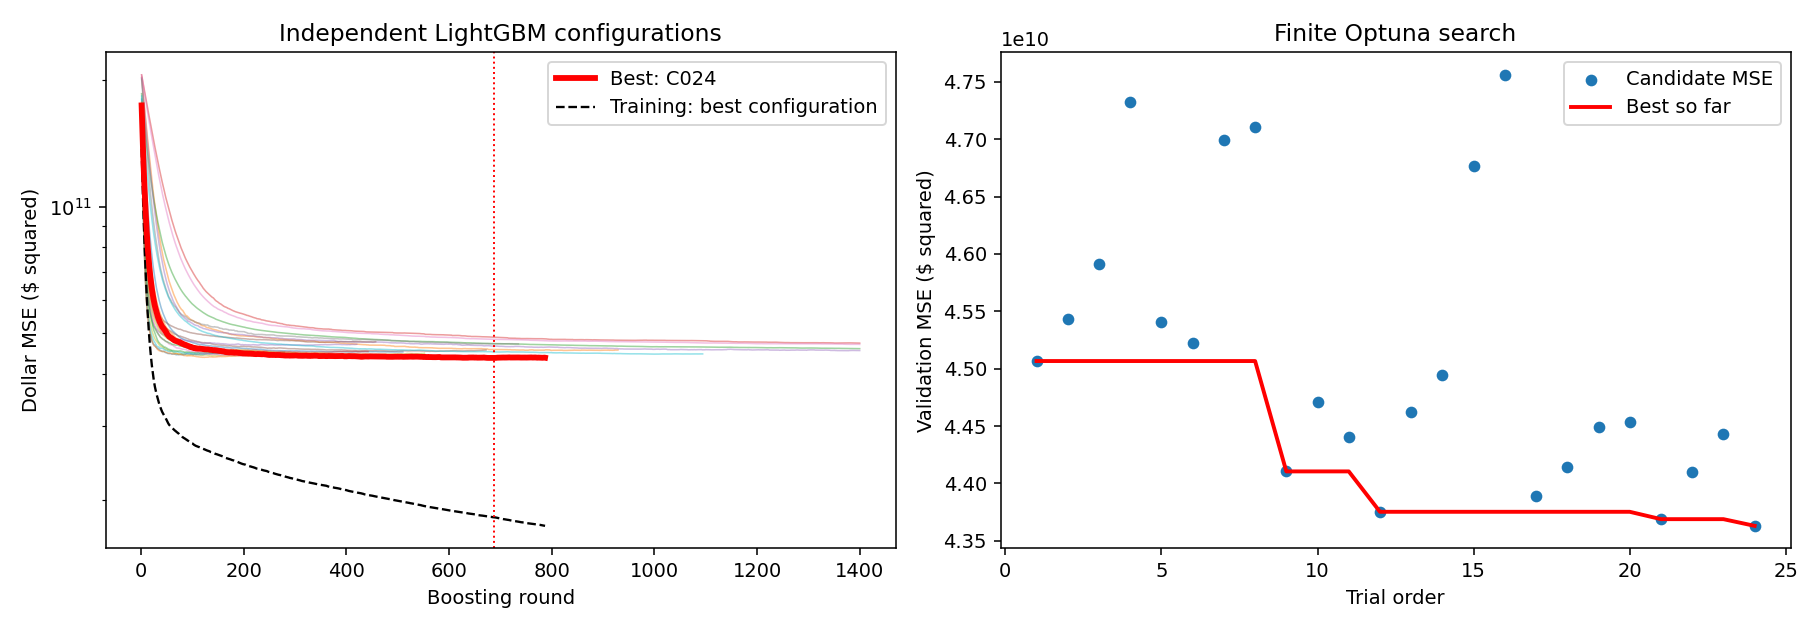

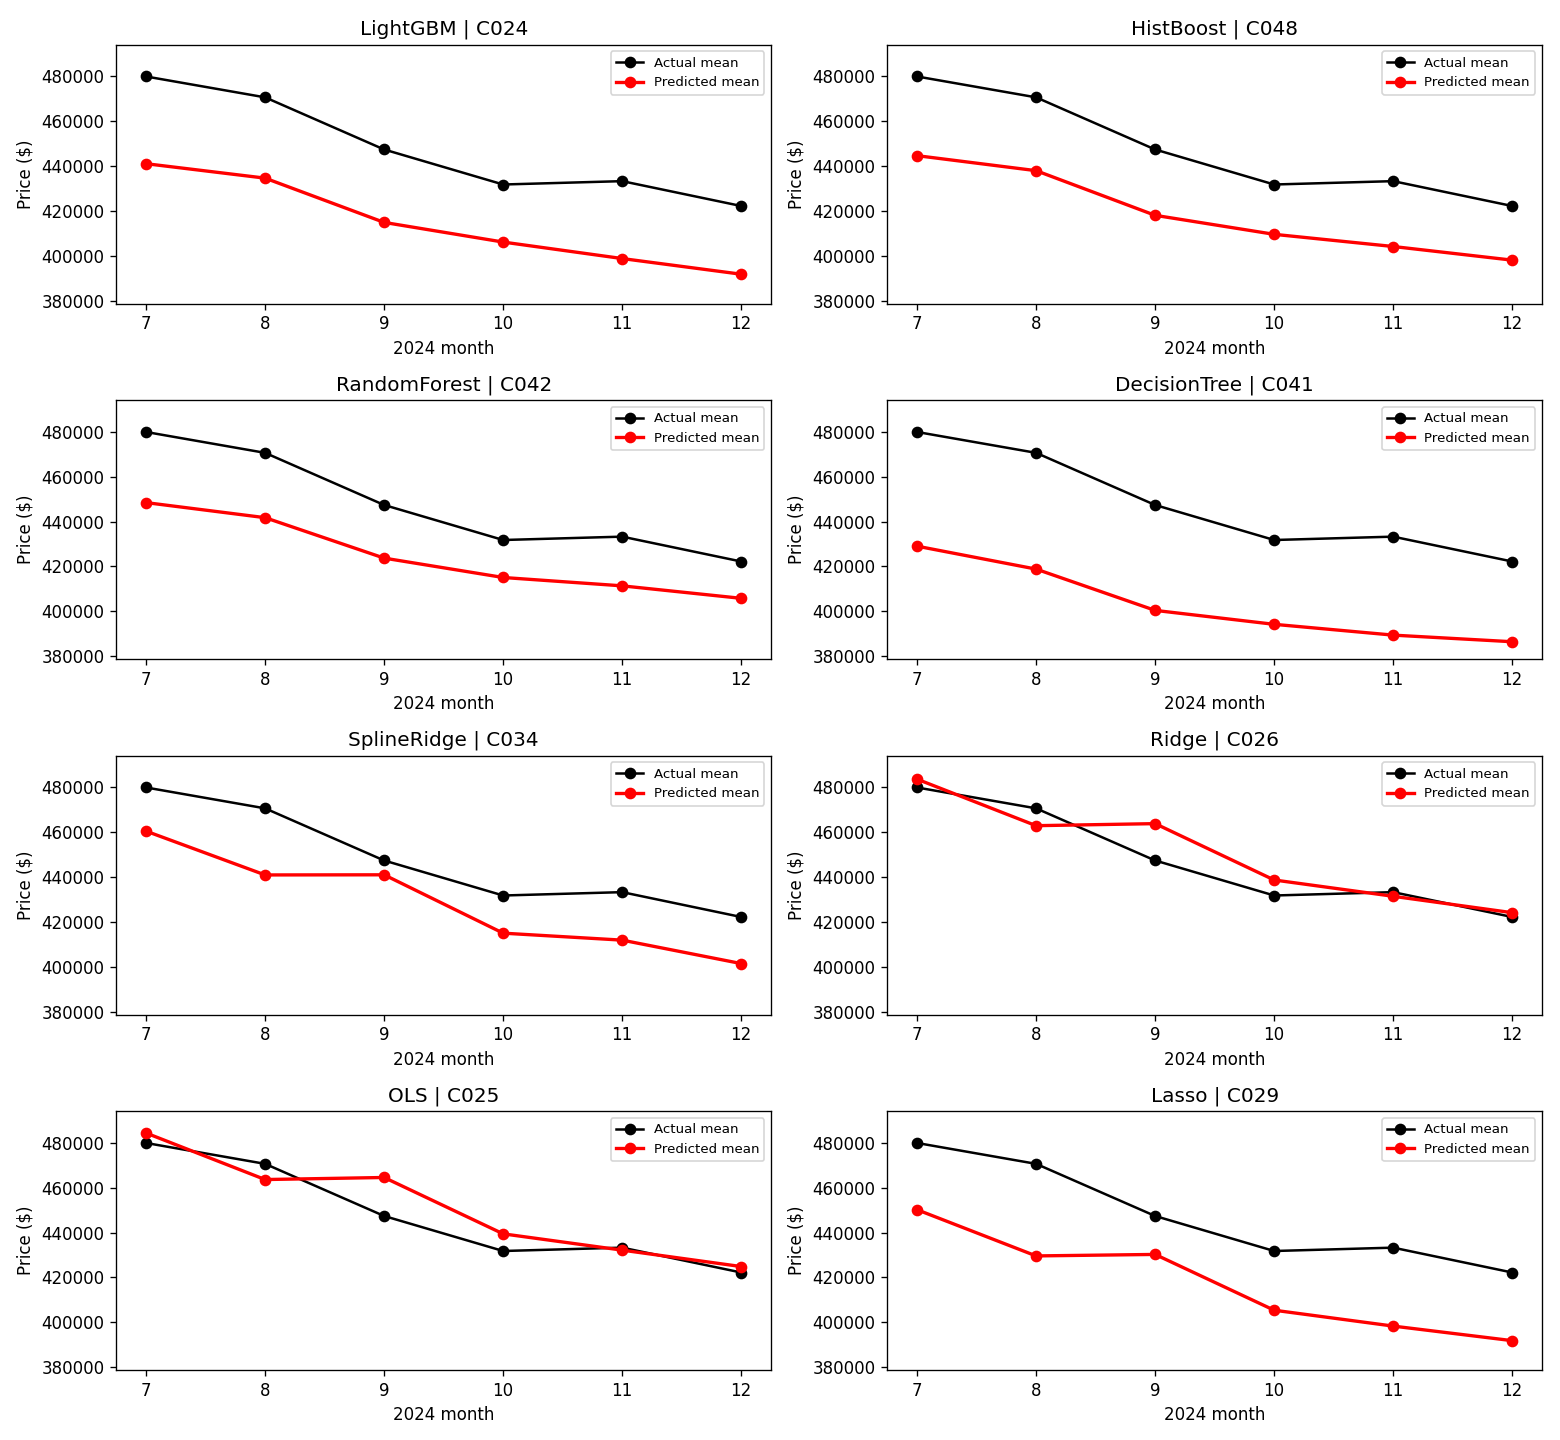

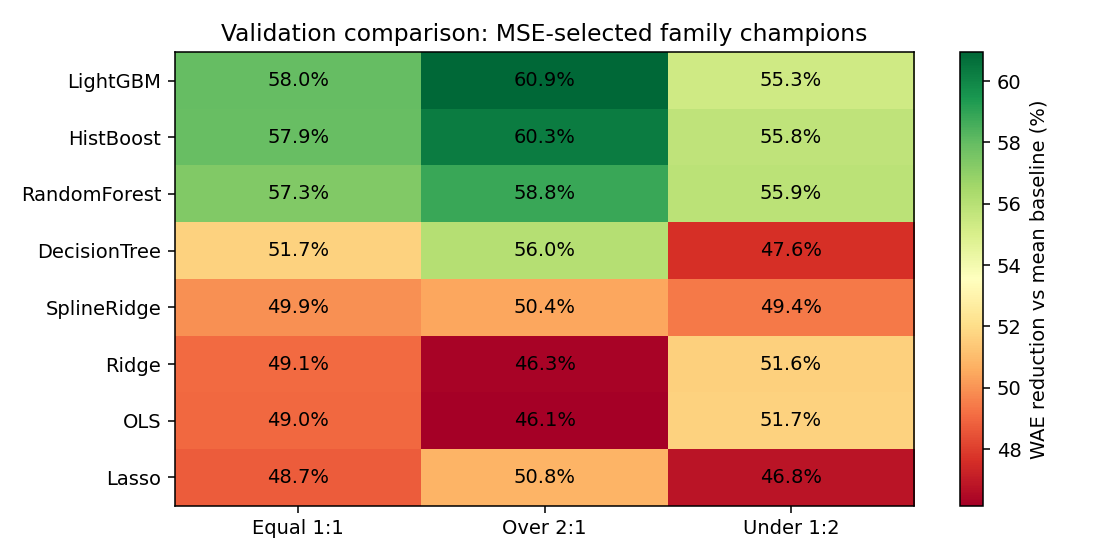

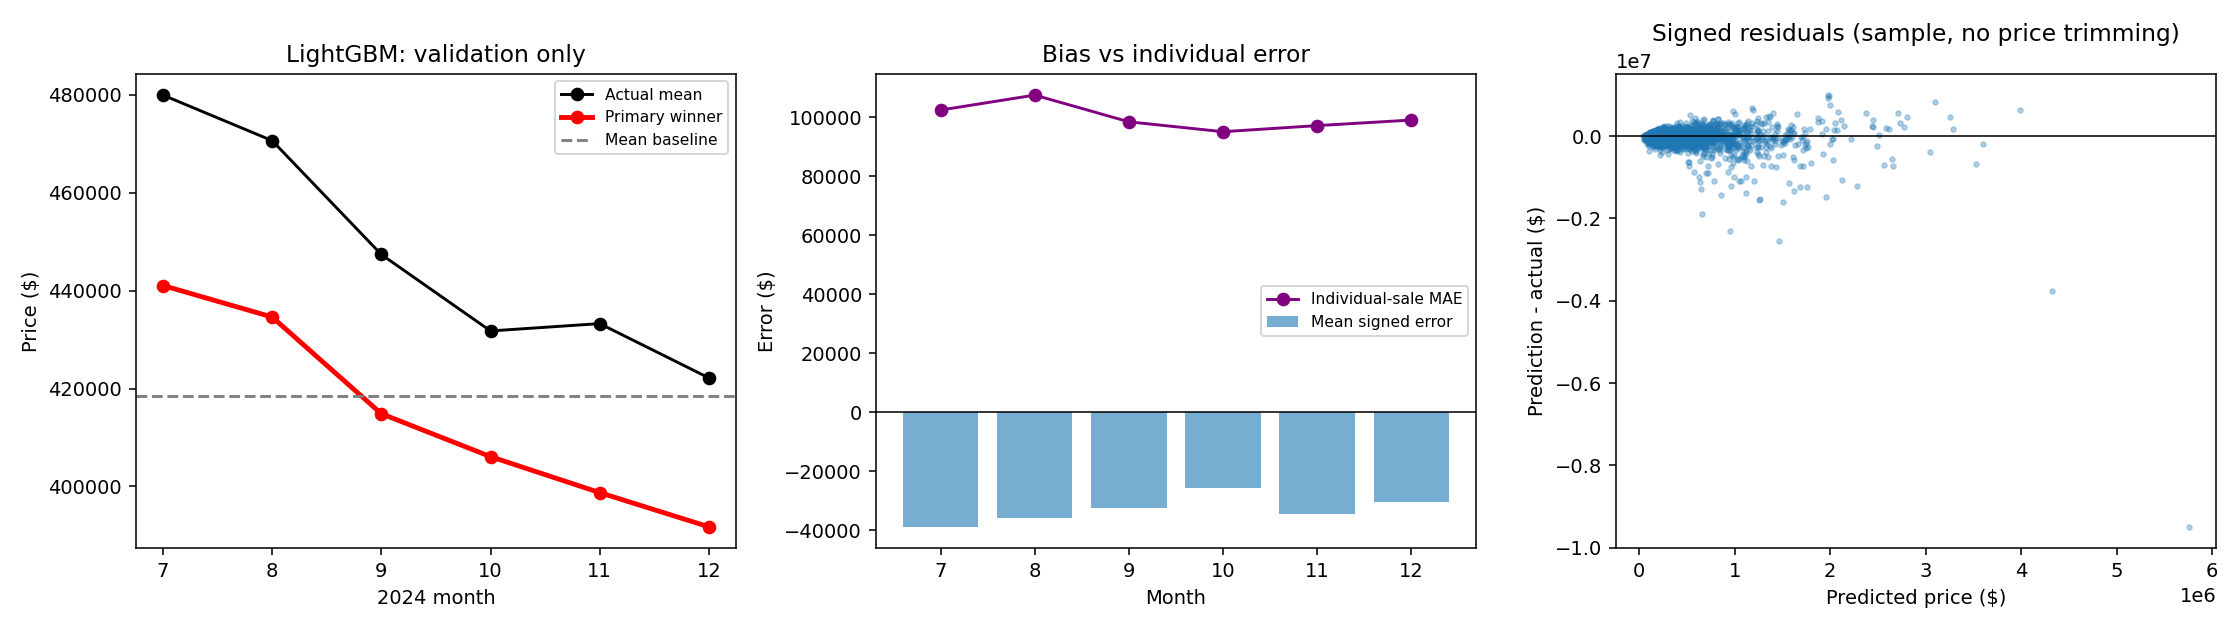

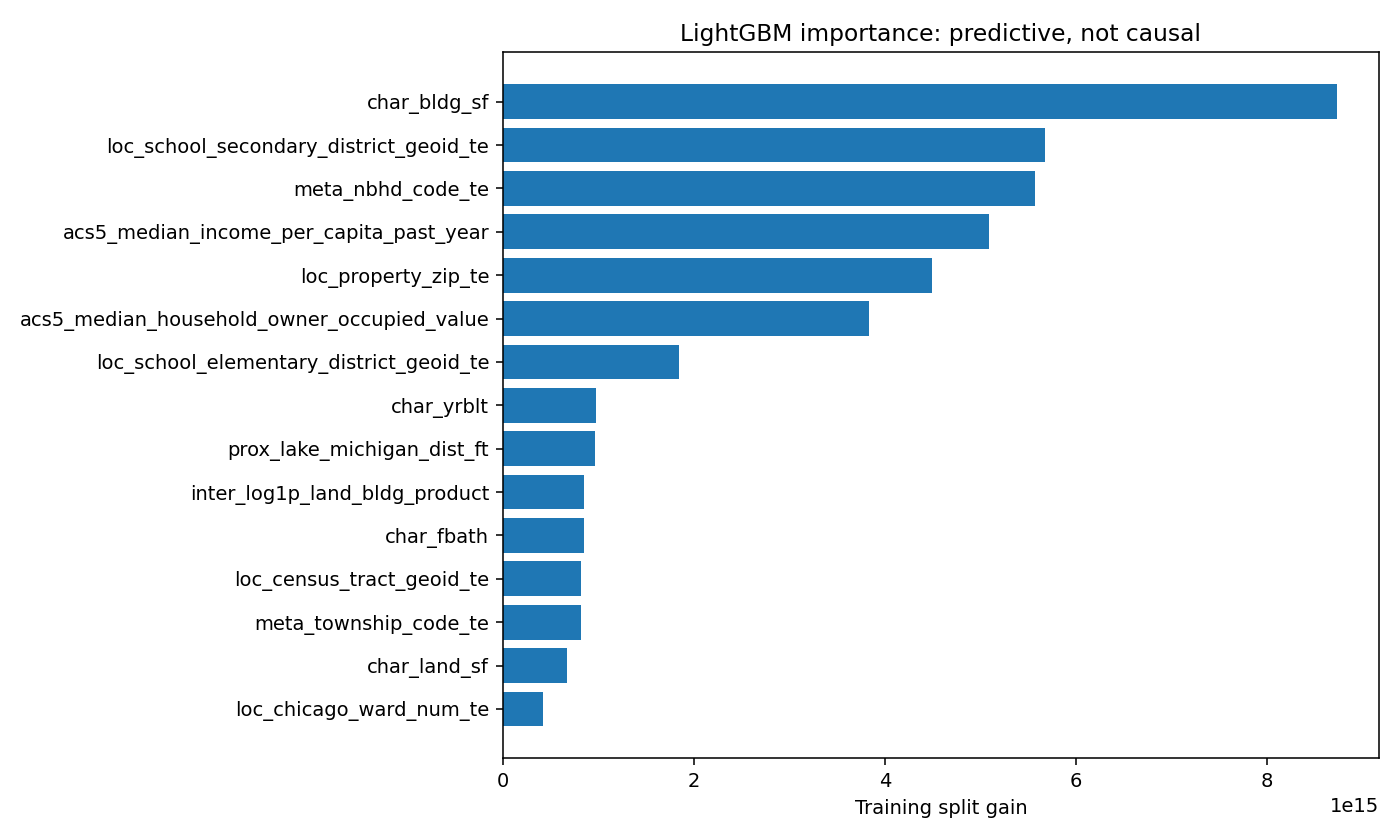

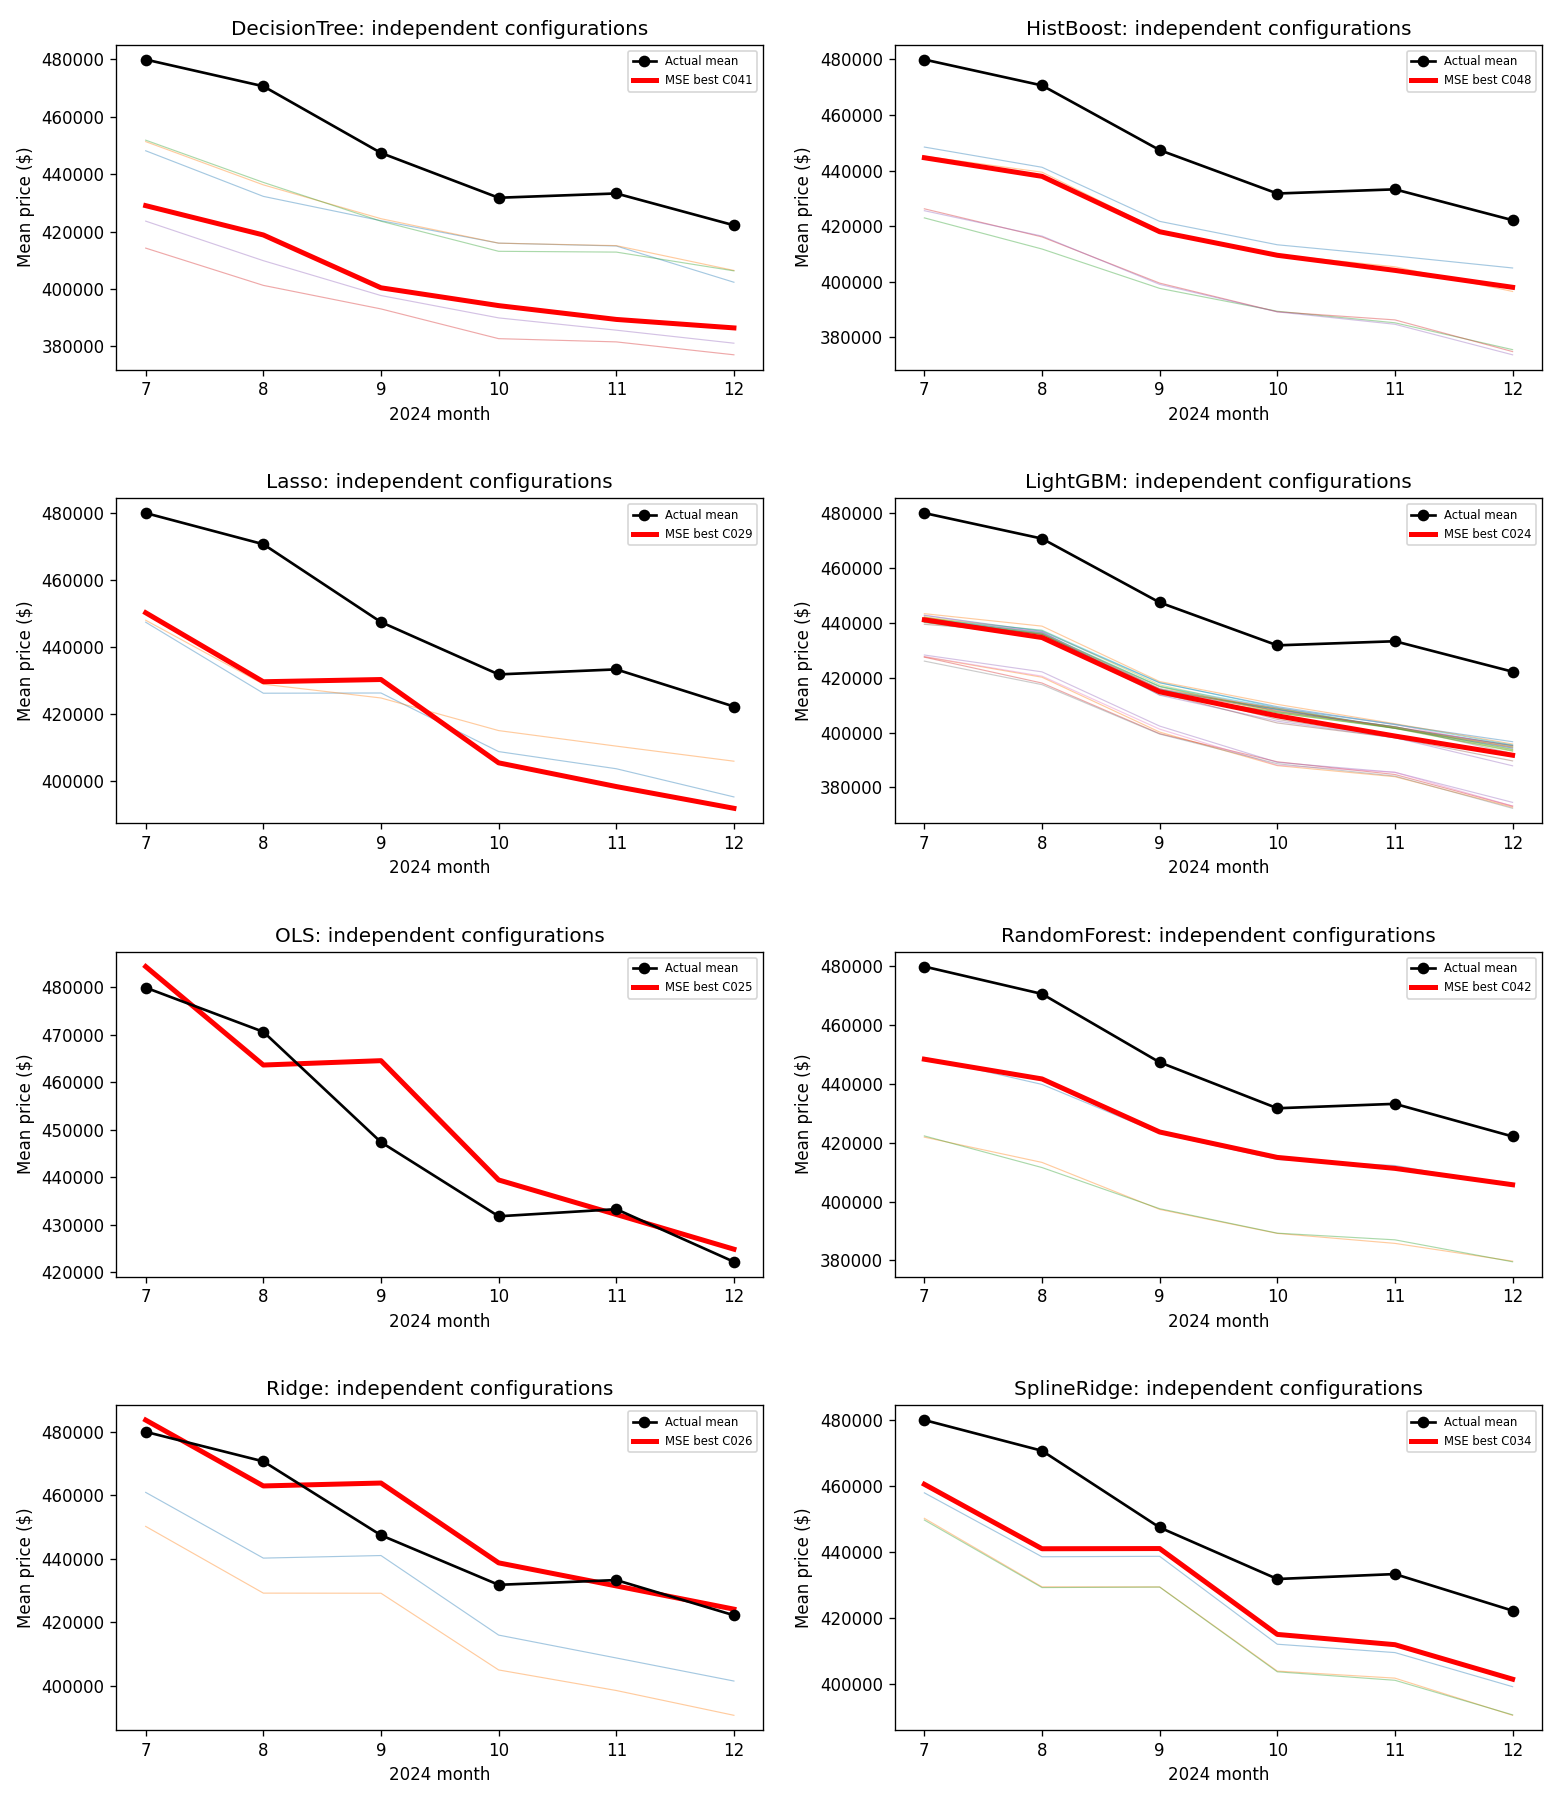

In [9]:
# 图1：LightGBM候选的原美元验证MSE随轮数变化；最佳MSE配置为粗红线。
lgb_best_id=family_best_models['LightGBM'][0]
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for cid,h in lgb_histories.items():
    best=cid==lgb_best_id
    curve=h['validation']['dollar_MSE']
    axes[0].plot(np.arange(1,len(curve)+1),curve,color='red' if best else None,
        lw=3 if best else .8,alpha=1 if best else .45,label=f'Best: {cid}' if best else None,
        zorder=5 if best else 1)
best_history=lgb_histories[lgb_best_id]['training']['dollar_MSE']
axes[0].plot(np.arange(1,len(best_history)+1),best_history,color='black',ls='--',lw=1.2,label='Training: best configuration')
axes[0].axvline(int(candidate_specs[lgb_best_id]['params']['n_estimators']),color='red',ls=':',lw=1)
axes[0].set(xlabel='Boosting round',ylabel='Dollar MSE ($ squared)',title='Independent LightGBM configurations')
axes[0].set_yscale('log');axes[0].legend()
lgb_scores=scores.loc[scores.family.eq('LightGBM')].reset_index(drop=True)
axes[1].scatter(np.arange(1,len(lgb_scores)+1),lgb_scores.MSE,s=25,label='Candidate MSE')
axes[1].plot(np.arange(1,len(lgb_scores)+1),lgb_scores.MSE.cummin(),color='red',lw=2,label='Best so far')
axes[1].set(xlabel='Trial order',ylabel='Validation MSE ($ squared)',title='Finite Optuna search')
axes[1].legend();fig.tight_layout();fig.savefig(OUT/'01_lightgbm_optimization.png',dpi=140);plt.close(fig)
show_saved('01_lightgbm_optimization.png')

# 图2：各族MSE冠军与同一批2024H2房屋的实际月均价；仅6个月，不能称全年趋势。
months=valid_df.sale_month.to_numpy();unique_months=np.sort(np.unique(months))
monthly=[]
for _,r in comparison_pool.iterrows():
    p=validation_predictions[r.candidate_id]
    for month in unique_months:
        mask=months==month
        monthly.append(dict(candidate_id=r.candidate_id,family=r.family,month=int(month),n=int(mask.sum()),
            actual_mean=float(y_valid[mask].mean()),predicted_mean=float(p[mask].mean()),
            MAE=float(np.mean(np.abs(p[mask]-y_valid[mask]))),mean_signed_error=float(np.mean(p[mask]-y_valid[mask]))))
monthly=pd.DataFrame(monthly);monthly.to_csv(OUT/'validation_monthly_predictions.csv',index=False)
n=len(comparison_pool);ncols=2;nrows=int(np.ceil(n/ncols))
fig,axes=plt.subplots(nrows,ncols,figsize=(13,3*nrows),squeeze=False)
for ax,(_,r) in zip(axes.ravel(),comparison_pool.iterrows()):
    m=monthly.loc[monthly.candidate_id.eq(r.candidate_id)]
    ax.plot(m.month,m.actual_mean,'ko-',label='Actual mean')
    ax.plot(m.month,m.predicted_mean,'o-',color='red',lw=2,label='Predicted mean')
    ax.set(title=f'{r.family} | {r.candidate_id}',xlabel='2024 month',ylabel='Price ($)')
    ax.set_xticks(unique_months);ax.legend(fontsize=8)
for ax in axes.ravel()[n:]:ax.set_visible(False)
shared_low=min(monthly.actual_mean.min(),monthly.predicted_mean.min())*.98
shared_high=max(monthly.actual_mean.max(),monthly.predicted_mean.max())*1.02
for ax in axes.ravel()[:n]:ax.set_ylim(shared_low,shared_high)
fig.tight_layout();fig.savefig(OUT/'02_family_champions_monthly.png',dpi=120);plt.close(fig)
show_saved('02_family_champions_monthly.png')

# 图3：WAE的排名变化。各列权重不同，比较列内排名与相对基准，而非跨列绝对大小。
wae_cols=['WAE_'+s for s in SCENARIOS]
matrix=comparison_pool.set_index('family')[wae_cols]
mean_baseline=baseline_scores.loc[baseline_scores.model.eq('Mean baseline')].iloc[0]
relative=matrix.copy()
for col in wae_cols:relative[col]=100*(1-matrix[col]/mean_baseline[col])
relative.to_csv(OUT/'validation_WAE_improvement_vs_mean_pct.csv')
fig,ax=plt.subplots(figsize=(8,max(4,len(relative)*.5)))
im=ax.imshow(relative.to_numpy(),cmap='RdYlGn',aspect='auto')
ax.set_xticks(range(3),['Equal 1:1','Over 2:1','Under 1:2'])
ax.set_yticks(range(len(relative)),relative.index)
for i in range(len(relative)):
    for j in range(3):ax.text(j,i,f'{relative.iloc[i,j]:.1f}%',ha='center',va='center')
fig.colorbar(im,ax=ax,label='WAE reduction vs mean baseline (%)')
ax.set_title('Validation comparison: MSE-selected family champions')
fig.tight_layout();fig.savefig(OUT/'03_WAE_scenario_comparison.png',dpi=140);plt.close(fig)
show_saved('03_WAE_scenario_comparison.png')

# 图4：主情景冠军价格走势、方向偏差和逐笔误差；月均相近不等于逐笔准确。
wp=validation_predictions[winner_id];wm=monthly.loc[monthly.candidate_id.eq(winner_id)]
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
axes[0].plot(wm.month,wm.actual_mean,'ko-',label='Actual mean')
axes[0].plot(wm.month,wm.predicted_mean,'ro-',lw=2.5,label='Primary winner')
axes[0].axhline(baseline_values['Mean baseline'],color='gray',ls='--',label='Mean baseline')
axes[0].set(title=f'{winner_row.family}: validation only',xlabel='2024 month',ylabel='Price ($)');axes[0].legend(fontsize=8)
axes[1].bar(wm.month,wm.mean_signed_error,label='Mean signed error',alpha=.6)
axes[1].plot(wm.month,wm.MAE,'o-',color='purple',label='Individual-sale MAE')
axes[1].axhline(0,color='black',lw=.8);axes[1].set(title='Bias vs individual error',xlabel='Month',ylabel='Error ($)');axes[1].legend(fontsize=8)
rng=np.random.default_rng(SEED);ix=rng.choice(len(y_valid),min(4000,len(y_valid)),replace=False)
axes[2].scatter(wp[ix],wp[ix]-y_valid[ix],s=6,alpha=.3)
axes[2].axhline(0,color='black',lw=.8)
axes[2].set(xlabel='Predicted price ($)',ylabel='Prediction - actual ($)',title='Signed residuals (sample, no price trimming)')
fig.tight_layout();fig.savefig(OUT/'04_primary_winner_diagnostics.png',dpi=140);plt.close(fig)
show_saved('04_primary_winner_diagnostics.png')

# 图5：LightGBM gain是训练损失下的分裂贡献，不是方向、因果效应或变量删除证据。
lgb_best=family_best_models['LightGBM'][1]
importance=pd.DataFrame({'feature':FEATURES,'gain':lgb_best.booster_.feature_importance(importance_type='gain')}).sort_values('gain',ascending=False)
importance.to_csv(OUT/'lightgbm_gain_importance.csv',index=False)
top=importance.head(15).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,6));ax.barh(top.feature,top.gain)
ax.set(xlabel='Training split gain',title='LightGBM importance: predictive, not causal')
fig.tight_layout();fig.savefig(OUT/'05_lightgbm_gain_importance.png',dpi=140);plt.close(fig)
show_saved('05_lightgbm_gain_importance.png')

# 图7：所有独立参数配置的月均预测线；粗红线是该族MSE冠军，黑线为实际。
# 此图横轴是月份，不是训练步骤；只有图1是Boosting逐轮优化曲线。
fig,axes=plt.subplots(4,2,figsize=(13,15),squeeze=False)
for ax,(_,best) in zip(axes.ravel(),champions.sort_values('family').iterrows()):
 actual=[float(y_valid[months==m].mean()) for m in unique_months]
 ax.plot(unique_months,actual,'ko-',lw=1.6,label='Actual mean',zorder=8)
 for _,r in scores.loc[scores.family.eq(best.family)].iterrows():
  pred=validation_predictions[r.candidate_id]
  values=[float(pred[months==m].mean()) for m in unique_months]
  is_best=r.candidate_id==best.candidate_id
  ax.plot(unique_months,values,color='red' if is_best else None,lw=3 if is_best else .7,
   alpha=1 if is_best else .4,zorder=7 if is_best else 1,label=f'MSE best {r.candidate_id}' if is_best else None)
 ax.set(title=f'{best.family}: independent configurations',xlabel='2024 month',ylabel='Mean price ($)');ax.set_xticks(unique_months);ax.legend(fontsize=7)
fig.tight_layout(h_pad=3.,w_pad=2.);fig.savefig(OUT/'07_configurations_monthly_curves.png',dpi=120);plt.close(fig);show_saved('07_configurations_monthly_curves.png')


## 9. 误差结构、业务含义与规则敏感性

验证误差最大的1%交易贡献了62.1%的总平方误差；这不是价格最高1%的定义。
MSE排名前两类的相对差距为2.1351%，只是数值差距，不声明统计等效或显著性。


### 两种选择规则的差异：只作解释，不事后改主规则
下表直接WAE重排只涵盖已经按MSE搜索过的配置，不能称为针对WAE充分调参的最优结果。主流程仍按既定的MSE族内→WAE族间规则。

scenario,MSE_champion_route_id,MSE_champion_route_family,MSE_champion_route_WAE,all_tested_direct_WAE_id,all_tested_direct_WAE_family,all_tested_direct_WAE,route_gap_pct
equal_1_1,C024,LightGBM,100223.824,C047,HistBoost,99834.425,0.390
over_2_under_1,C024,LightGBM,133726.531,C007,LightGBM,127205.189,5.127
under_2_over_1,C042,RandomForest,164638.099,C047,HistBoost,164079.060,0.341


price_band,n,median_actual,MAE,RMSE,mean_signed_error,overvaluation_rate,WAE_over_2_under_1
below_train_P10,1510,85000.0,74111.457,95714.272,71851.550,0.938,147092.961
train_P10_to_P90,14600,340000.0,73305.641,103180.223,-20199.945,0.346,99858.490
above_train_P90,2022,1110000.0,314088.877,554559.748,-205683.901,0.257,368291.365


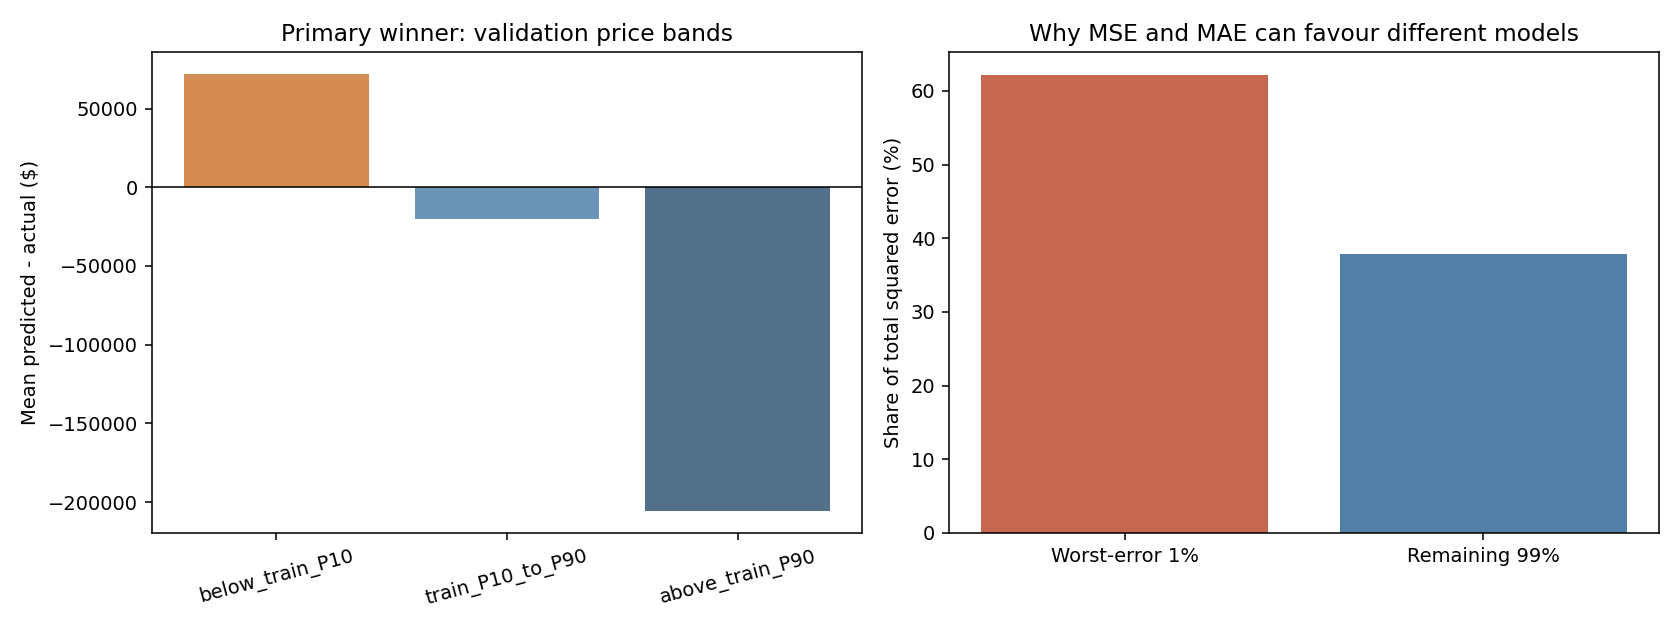

### LightGBM分组置换诊断
误差增加越大表示该模型越依赖该组信息；不是因果、增益不可相加，3次置换标准差不是泛化置信区间。负值也不能自动作为删除依据。

columns,MSE_increase_mean,MSE_increase_sd,primary_WAE_increase_mean
69,5.881798e+10,3.502059e+08,86697.76
32,3.481769e+10,1.573222e+09,92176.99
25,2.347157e+10,3.432150e+08,44779.40
11,7.976747e+09,1.739232e+08,42354.42
3,6.778445e+09,2.304202e+08,13919.05
37,6.327786e+09,3.110638e+08,5023.81
21,2.700527e+08,1.182658e+08,293.41
11,1.692228e+07,3.443552e+07,64.45


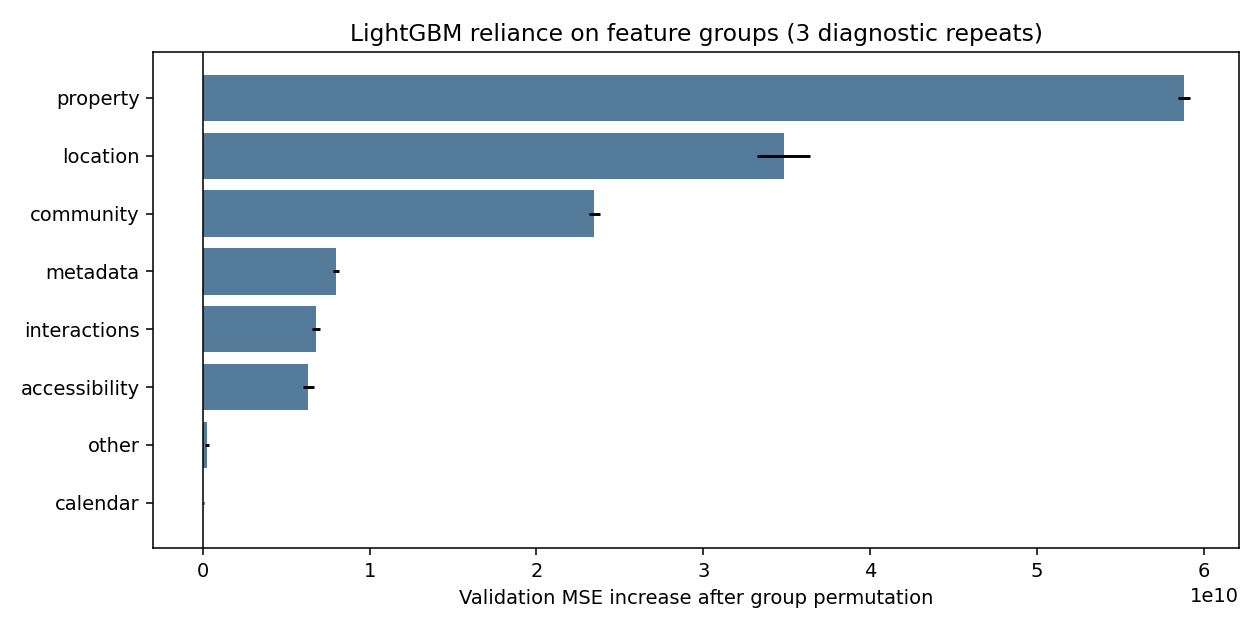

In [10]:
# 主规则不变；这一节解释“按MSE调参再按WAE选族”与直接按WAE挑配置的差异。
eligible_pool=scores.loc[scores.eligible_for_selection].copy()
comparison_routes=[]
for scenario in SCENARIOS:
    col='WAE_'+scenario
    direct=eligible_pool.sort_values([col,'candidate_id']).iloc[0]
    main_route=comparison_pool.loc[comparison_pool.candidate_id.eq(scenario_winners[scenario])].iloc[0]
    comparison_routes.append(dict(scenario=scenario,
        MSE_champion_route_id=main_route.candidate_id,MSE_champion_route_family=main_route.family,
        MSE_champion_route_WAE=main_route[col],
        all_tested_direct_WAE_id=direct.candidate_id,all_tested_direct_WAE_family=direct.family,
        all_tested_direct_WAE=direct[col],
        route_gap_pct=100*(main_route[col]/direct[col]-1)))
route_table=pd.DataFrame(comparison_routes)
route_table.to_csv(OUT/'selection_rule_sensitivity.csv',index=False)
display(Markdown('### 两种选择规则的差异：只作解释，不事后改主规则\n下表直接WAE重排只涵盖已经按MSE搜索过的配置，不能称为针对WAE充分调参的最优结果。主流程仍按既定的MSE族内→WAE族间规则。'))
display(route_table.round(3))

# 使用训练售价阈值，验证价位只用于事后误差诊断；不用于重新训练或选择配置。
wp=validation_predictions[winner_id]
low,high=np.quantile(y_train,[.1,.9])
bands=pd.cut(y_valid,[-np.inf,low,high,np.inf],labels=['below_train_P10','train_P10_to_P90','above_train_P90'])
band_rows=[]
for band in bands.categories:
    mask=np.asarray(bands==band)
    if not mask.any():continue
    sc=score_predictions(y_valid[mask],wp[mask])
    band_rows.append(dict(price_band=str(band),mean_actual=float(y_valid[mask].mean()),
        median_actual=float(np.median(y_valid[mask])),**sc))
band_table=pd.DataFrame(band_rows)
band_table.to_csv(OUT/'primary_validation_price_band_diagnostics.csv',index=False)
display(band_table[['price_band','n','median_actual','MAE','RMSE','mean_signed_error','overvaluation_rate','WAE_'+PRIMARY_SCENARIO]].round(3))
error=wp-y_valid;squared=np.square(error)
k=max(1,int(np.ceil(.01*len(error))))
tail_share=float(np.partition(squared,-k)[-k:].sum()/squared.sum())
best_two=champions.sort_values(['MSE','candidate_id']).head(2)
relative_mse_gap=100*(best_two.MSE.iloc[1]/best_two.MSE.iloc[0]-1)
diagnostic_summary=dict(training_price_P10=float(low),training_price_P90=float(high),
    top_one_percent_error_count=k,top_one_percent_share_squared_error=tail_share,
    first_two_MSE_families=best_two.family.tolist(),relative_MSE_gap_pct=float(relative_mse_gap),
    caution='No statistical equivalence claim; no property-cluster CI without IDs.')
write_json(OUT/'diagnostic_summary.json',diagnostic_summary)
print(f'验证误差最大的1%交易贡献了{tail_share:.1%}的总平方误差；这不是价格最高1%的定义。')
print(f'MSE排名前两类的相对差距为{relative_mse_gap:.4f}%，只是数值差距，不声明统计等效或显著性。')
large=np.argsort(np.abs(error))[-20:][::-1]
pd.DataFrame({'row_id':VALID_IDS[large],'actual_price':y_valid[large],'prediction':wp[large],
    'signed_error':error[large],'sale_month':valid_df.sale_month.iloc[large].to_numpy()}).to_csv(OUT/'largest_validation_errors_for_review.csv',index=False)

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar(band_table.price_band,band_table.mean_signed_error,color=['#d58c52','#6c94b6','#53708a'][:len(band_table)])
axes[0].axhline(0,color='black',lw=.8);axes[0].tick_params(axis='x',rotation=15)
axes[0].set(ylabel='Mean predicted - actual ($)',title='Primary winner: validation price bands')
axes[1].bar(['Worst-error 1%','Remaining 99%'],[tail_share*100,(1-tail_share)*100],color=['#c66850','#527fa7'])
axes[1].set(ylabel='Share of total squared error (%)',title='Why MSE and MAE can favour different models')
fig.tight_layout();fig.savefig(OUT/'06_error_tradeoffs.png',dpi=140);plt.close(fig)
show_saved('06_error_tradeoffs.png')

# 分组置换：共同打乱一类列，保留类内相关结构；仍可能破坏跨组相关性。
# 验证集已经用于调参，这只是解释性诊断，不作为新的特征筛选规则。
groups={
 'property':[c for c in FEATURES if c.startswith('char_') or c=='house_age'],
 'location':[c for c in FEATURES if c.startswith('loc_') or c=='is_Chicago'],
 'accessibility':[c for c in FEATURES if c.startswith('prox_')],
 'community':[c for c in FEATURES if c.startswith('acs5_')],
 'other':[c for c in FEATURES if c.startswith('other_')],
 'interactions':[c for c in FEATURES if c.startswith('inter_')],
 'metadata':[c for c in FEATURES if c.startswith('meta_')],
 'calendar':[c for c in FEATURES if c.startswith('month_')]}
remaining=set(FEATURES)-set(c for g in groups.values() for c in g)
if remaining:groups['remaining']=sorted(remaining)
base_model=family_best_models['LightGBM'][1];best_spec=candidate_specs[lgb_best_id]
base_pred=validation_predictions[lgb_best_id];base_mse=mean_squared_error(y_valid,base_pred)
rng=np.random.default_rng(SEED);perm_rows=[]
for group,cols in groups.items():
 if not cols:continue
 for repeat in range(3):
  xp=X_valid.copy();order=rng.permutation(len(xp));xp.loc[:,cols]=xp[cols].to_numpy()[order]
  pp=to_dollars(base_model.predict(xp),best_spec['target'])
  perm_rows.append(dict(group=group,columns=len(cols),repeat=repeat+1,
   MSE_increase=float(mean_squared_error(y_valid,pp)-base_mse),
   primary_WAE_increase=weighted_absolute_error(y_valid,pp,SCENARIOS[PRIMARY_SCENARIO])-weighted_absolute_error(y_valid,base_pred,SCENARIOS[PRIMARY_SCENARIO])))
permutation_results=pd.DataFrame(perm_rows);permutation_results.to_csv(OUT/'lightgbm_group_permutation_diagnostics.csv',index=False)
perm_summary=permutation_results.groupby('group').agg(columns=('columns','first'),MSE_increase_mean=('MSE_increase','mean'),MSE_increase_sd=('MSE_increase','std'),primary_WAE_increase_mean=('primary_WAE_increase','mean')).sort_values('MSE_increase_mean',ascending=False)
display(Markdown('### LightGBM分组置换诊断\n误差增加越大表示该模型越依赖该组信息；不是因果、增益不可相加，3次置换标准差不是泛化置信区间。负值也不能自动作为删除依据。'));display(perm_summary.round(2));perm_summary.to_csv(OUT/'lightgbm_group_permutation_summary.csv')
fig,ax=plt.subplots(figsize=(9,4.5));per=perm_summary.iloc[::-1]
ax.barh(per.index,per.MSE_increase_mean,xerr=per.MSE_increase_sd,color='#557b9a');ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Validation MSE increase after group permutation',title='LightGBM reliance on feature groups (3 diagnostic repeats)')
fig.tight_layout();fig.savefig(OUT/'08_group_permutation.png',dpi=140);plt.close(fig);show_saved('08_group_permutation.png')


In [11]:
display(Markdown('### 每族MSE冠军的完整三情景指标与参数'))
display(champions[['family','candidate_id','MSE','RMSE','MAE','R2']+['WAE_'+s for s in SCENARIOS]].sort_values('MSE').round(3))
display(champions[['family','candidate_id','target','params']])
# 4c验证演示：固定主冠军，不随情景更换模型。
mean_row=baseline_scores.loc[baseline_scores.model.eq('Mean baseline')].iloc[0]
fixed=[]
for scenario,w in SCENARIOS.items():
 col='WAE_'+scenario
 fixed.append(dict(scenario=scenario,model=winner_row.family,candidate=winner_id,model_WAE=winner_row[col],
 baseline_WAE=mean_row[col],reduction_pct=100*(1-winner_row[col]/mean_row[col])))
fixed=pd.DataFrame(fixed);fixed.to_csv(OUT/'4c_validation_fixed_primary_predictions.csv',index=False)
display(Markdown('### 4c验证演示：同一个主模型的预测保持不变'));display(fixed.round(3))
raw_best=scores.loc[scores.family.eq('LightGBM')&scores.target.eq('raw')].sort_values('MSE').iloc[0]
log_best=scores.loc[scores.family.eq('LightGBM')&scores.target.eq('log1p')].sort_values('MSE').iloc[0]
display(pd.DataFrame([raw_best,log_best])[['candidate_id','target','MSE','MAE','R2','WAE_'+PRIMARY_SCENARIO]])
capacity=pd.DataFrame([dict(candidate_id=cid,best_round=candidate_specs[cid]['params']['n_estimators'],
 recorded_rounds=len(h['validation']['dollar_MSE']),hit_round_budget=len(h['validation']['dollar_MSE'])>=MAX_BOOST_ROUNDS)
 for cid,h in lgb_histories.items()])
capacity.to_csv(OUT/'lightgbm_round_budget_diagnostics.csv',index=False)
print('LightGBM达到最大记录轮数的配置数：',int(capacity.hit_round_budget.sum()),'；这可能限制有限搜索的最优性，不据测试结果自动扩展。')
MSE_best=champions.sort_values('MSE').iloc[0]
worst_band=band_table.loc[band_table['WAE_'+PRIMARY_SCENARIO].idxmax()]
imp=importance.head(5).feature.tolist()
primarycol='WAE_'+PRIMARY_SCENARIO
english=f'''# M4 evidence and report support — validation only

## 3f: selection and practical meaning
Using the supplied chronological development split (54,853 training sales and 18,132 validation sales), we excluded both price targets from the 209 encoded predictors and corrected the validation October dummy. We trained {len(scores)} configurations across {len(champions)} model families. Within each family, the eligible configuration with the lowest original-dollar validation MSE was retained. Comparing these family champions under the prespecified overvaluation-to-undervaluation weights of 2:1 selected {winner_row.family} ({winner_id}). Its validation MSE was {winner_row.MSE:,.2f} dollars squared, RMSE ${winner_row.RMSE:,.2f}, MAE ${winner_row.MAE:,.2f}, and R-squared {winner_row.R2:.4f}. Its primary WAE was ${winner_row[primarycol]:,.2f}, compared with ${mean_row[primarycol]:,.2f} for the training-mean baseline, a reduction of {100*(1-winner_row[primarycol]/mean_row[primarycol]):.2f}%.

The lowest-MSE family champion was {MSE_best.family} ({MSE_best.candidate_id}); this need not be the final business-loss winner. The two-stage rule does not identify the globally WAE-optimal parameter configuration. Search budgets differed across families, and validation reuse creates selection optimism. R-squared measures explained variation relative to the validation mean, not the percentage of correct valuations. MAE is the mean absolute sale-level discrepancy, not an error bound for an individual home. Lower average errors support faster initial review and prioritisation, but substantial tail errors require human judgement. The results describe sale-price prediction, not tax liabilities or causal price effects.

## 4c: fixed-prediction sensitivity — validation illustration
The 2:1 main scenario reflects a preference to reduce overly high valuation errors while still assigning importance to underestimation. It expresses priorities, not measured financial costs. The same primary-model predictions and the same training-mean predictions were rescored in the alternatives:

'''+fixed.to_markdown(index=False,floatfmt=',.2f')+f'''

Relative to the mean baseline, the primary model {'retained its advantage in all scenarios' if (fixed.reduction_pct>0).all() else 'did not retain its advantage in every scenario'}. Model rankings among family champions may change with directional priorities; this does not imply that the underlying predictions changed. WAE magnitudes should be compared within scenarios because increasing a directional weight mechanically raises the metric. This paragraph uses development validation evidence; final 4c claims must be checked on the locked 2025 evaluation rather than describing these numbers as test results.

## 4d: pilot judgement and limits
The performance reduction supports consideration of a supervised valuation-review pilot, subject to confirming upstream reproducibility, raw transaction membership and deployment-time availability. It does not justify automatic assessments. Validation mean signed error was ${winner_row.mean_signed_error:,.2f}, and {winner_row.overvaluation_rate:.1%} of transactions were overestimated. The highest-error price band under the main scenario was {worst_band.price_band}, with WAE ${worst_band[primarycol]:,.2f}. Error-based risk is observable only after sale; a live review queue should instead use available warning signals such as atypical property values, missing inputs or predictions outside the training range. Monitor errors by period, township, property type and price band after outcomes arrive. We cannot define production cutoffs or equity guarantees from these aggregate scores alone.

## Boosting interpretation
The leading LightGBM training-gain columns were {', '.join(imp)}. Gain describes the fitted model's training split contributions and is not a causal coefficient, a direction of price change or evidence that low-ranked variables can safely be deleted. Correlated and encoded columns can split importance. Dollar-MSE tuning gives greater influence to large misses; the largest-error 1% of validation sales accounted for {tail_share:.1%} of the primary model's total squared error. Monthly averages describe the sold-property mix and can hide individual errors.

## 5d: hypothetical business example (under 150 words)
The valuer should not automatically subtract the $30,000 repair quote from the $400,000 prediction. The model uses archived information and has not observed the major damage, so its estimate may describe a different condition. Repair cost and market-value loss are not necessarily equal: buyers may discount uncertainty, disruption or remaining defects, and repairs may partly improve the property beyond its previous condition. Obtain the full inspection, confirm the damage date and scope, assess habitability and structural implications, verify an independent repair estimate, and examine comparable sales of damaged and repaired homes. An appropriately qualified valuer should estimate the current as-is value, document any adjustment and its uncertainty, and explain how the model estimate was used as a reference. A mechanical $370,000 conclusion is not supported by the quote alone.

## 7d: business-interpretation reflection template (complete honestly; at most 180 words)
1. Initial view and AI use: state what you originally believed, the tool, actual date and a short prompt/excerpt about interpreting directional WAE or using a repair quote.
2. Check: cite the fixed-prediction three-scenario table from your executed code, or inspect the $400,000/$30,000 case against the model's archived inputs. State what you personally checked and found.
3. Decision: explain what advice you accepted, changed or rejected, and how it affected your report or proposed valuation process.
4. Learning and uncertainty: distinguish business priorities from measured costs, and price-prediction evidence from a justified condition adjustment. Identify missing current-condition or market evidence. Do not invent initial beliefs, checks or personal contributions.
'''
(OUT/'M4_report_evidence_EN.md').write_text(english,encoding='utf-8')
cn=f'''### 本次重新训练结果

- 以美元MSE最低选每族冠军；跨族主情景最终模型：**{winner_row.family} / {winner_id}**。
- 主情景WAE **${winner_row[primarycol]:,.2f}**；均值基线 **${mean_row[primarycol]:,.2f}**；下降 **{100*(1-winner_row[primarycol]/mean_row[primarycol]):.2f}%**。
- 最低MSE族冠军：**{MSE_best.family} / {MSE_best.candidate_id}**；RMSE **${MSE_best.RMSE:,.2f}**。业务WAE冠军不必等于MSE冠军。
- LightGBM的raw/log配置均按还原后的美元MSE比较；最佳参数完整见冠军表及model_lock.json。重要性只是预测贡献，不是因果效应。
- 误差最大的1%交易贡献了 **{tail_share:.1%}** 平方误差。月均趋势贴合不能代替逐笔准确度。
- 主模型相对均值基准在三情景下{'都保留优势' if (fixed.reduction_pct>0).all() else '并非都保留优势'}。改变权重只重新计分，不重新训练或更换4c主模型。

本次为验证结果，尚未评价2025。需要真实镇区、交易ID和属性类型字段才能完成4b或物业聚类不确定性评估。英文3f、4c验证示例、4d、5d及7d提示已保存为M4_report_evidence_EN.md；正式报告不能把验证结果改称测试结果。
'''
display(Markdown(cn));(OUT/'M4_result_summary_CN.md').write_text(cn,encoding='utf-8')

# 使用已读取的97变量解释表建立已编码列到原始字段的可追溯目录。
# raw_unit描述原始字段单位，当前矩阵经过变换，不能把其数值直接当作该单位。
raw_dictionary=pd.DataFrame([{'variable': 'loc_property_city', 'label': 'Property City', 'definition': 'Property City', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_property_zip', 'label': 'Property Zip Code', 'definition': 'Property Zip Code', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_longitude', 'label': 'Longitude', 'definition': 'Longitude', 'unit': 'degrees', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_latitude', 'label': 'Latitude', 'definition': 'Latitude', 'unit': 'degrees', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_yrblt', 'label': 'Year Built', 'definition': 'Year Built', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_bldg_sf', 'label': 'Building Square Feet', 'definition': 'Building Square Feet', 'unit': 'square feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_land_sf', 'label': 'Land Square Feet', 'definition': 'Land Square Feet', 'unit': 'square feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_beds', 'label': 'Bedrooms', 'definition': 'Bedrooms', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_rooms', 'label': 'Rooms', 'definition': 'Rooms', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_fbath', 'label': 'Full Baths', 'definition': 'Full Baths', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_hbath', 'label': 'Half Baths', 'definition': 'Half Baths', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_frpl', 'label': 'Fireplaces', 'definition': 'Fireplaces', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_type_resd', 'label': 'Type of Residence', 'definition': 'Type of Residence', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_cnst_qlty', 'label': 'Construction Quality', 'definition': 'Construction Quality', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_apts', 'label': 'Apartments', 'definition': 'Apartments', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_tp_dsgn', 'label': 'Cathedral Ceiling', 'definition': 'Cathedral Ceiling', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_attic_fnsh', 'label': 'Attic Finish', 'definition': 'Attic Finish', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_gar1_att', 'label': 'Garage 1 Attached', 'definition': 'Garage 1 Attached', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_gar1_area', 'label': 'Garage 1 Area Included', 'definition': 'Garage 1 Area Included', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_gar1_size', 'label': 'Garage 1 Size', 'definition': 'Garage 1 Size', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_gar1_cnst', 'label': 'Garage 1 Ext. Wall Material', 'definition': 'Garage 1 Ext. Wall Material', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_attic_type', 'label': 'Attic Type', 'definition': 'Attic Type', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_bsmt', 'label': 'Basement Type', 'definition': 'Basement Type', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_ext_wall', 'label': 'Exterior Wall Material', 'definition': 'Exterior Wall Material', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_heat', 'label': 'Central Heating', 'definition': 'Central Heating', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_bsmt_fin', 'label': 'Basement Finish', 'definition': 'Basement Finish', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_roof_cnst', 'label': 'Roof Material', 'definition': 'Roof Material', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_use', 'label': 'Single vs. Multi-family Use', 'definition': 'Single vs. Multi-family Use', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_porch', 'label': 'Porch', 'definition': 'Porch', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_air', 'label': 'Central Air Conditioning', 'definition': 'Central Air Conditioning', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_ncu', 'label': 'Number of Commercial Units', 'definition': 'Number of Commercial Units', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'char_tp_plan', 'label': 'Design Plan', 'definition': 'Design Plan', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_census_puma_geoid', 'label': 'Census Puma GEOID', 'definition': 'Census Puma GEOID', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_census_tract_geoid', 'label': 'Census Tract GEOID', 'definition': 'Census Tract GEOID', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_cook_municipality_name', 'label': 'Municipality', 'definition': 'Municipality recorded in the archived property location data.', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_chicago_ward_num', 'label': 'Chicago ward', 'definition': 'Chicago ward code. Usually missing outside Chicago.', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_chicago_community_area_name', 'label': 'Chicago Community Area Name', 'definition': 'Chicago Community Area Name', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_school_elementary_district_geoid', 'label': 'School Elementary District GEOID', 'definition': 'School Elementary District GEOID', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_school_secondary_district_geoid', 'label': 'School Secondary District GEOID', 'definition': 'School Secondary District GEOID', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_school_unified_district_geoid', 'label': 'School Unified District GEOID', 'definition': 'School Unified District GEOID', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_tax_special_service_area_num', 'label': 'Special Service Area Number', 'definition': 'Special Service Area Number', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_tax_tif_district_num', 'label': 'TIF District Number', 'definition': 'TIF District Number', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_misc_unincorporated_area_bool', 'label': 'Unincorporated area', 'definition': 'Indicator that the property lies in an unincorporated area.', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_env_flood_fema_sfha', 'label': 'FEMA Special Flood Hazard Area', 'definition': 'FEMA Special Flood Hazard Area', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_env_flood_fs_factor', 'label': 'First Street Factor', 'definition': 'First Street Factor', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_env_flood_fs_risk_direction', 'label': 'First Street Risk Direction', 'definition': 'First Street Risk Direction', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_env_ohare_noise_contour_no_buffer_bool', 'label': "O'Hare Noise Contour No Buffer Boolean", 'definition': "O'Hare Noise Contour No Buffer Boolean", 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_env_airport_noise_dnl', 'label': 'Airport Noise DNL', 'definition': 'Airport Noise DNL', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_access_cmap_walk_nta_score', 'label': 'CMAP Walkability Score (No Transit)', 'definition': 'CMAP Walkability Score (No Transit)', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'loc_access_cmap_walk_total_score', 'label': 'CMAP Walkability Total Score', 'definition': 'CMAP Walkability Total Score', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_num_pin_in_half_mile', 'label': 'Number of PINs in Half Mile', 'definition': 'Number of PINs in Half Mile', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_num_bus_stop_in_half_mile', 'label': 'Number of Bus Stops in Half Mile', 'definition': 'Number of Bus Stops in Half Mile', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_num_foreclosure_per_1000_pin_past_5_years', 'label': 'Number of Foreclosures Per 1000 PINs (Past 5 Years)', 'definition': 'Number of Foreclosures Per 1000 PINs (Past 5 Years)', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_num_school_in_half_mile', 'label': 'Number of Schools in Half Mile', 'definition': 'Number of Schools in Half Mile', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_num_school_with_rating_in_half_mile', 'label': 'Number of Schools with Rating in Half Mile', 'definition': 'Number of Schools with Rating in Half Mile', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_avg_school_rating_in_half_mile', 'label': 'Average School Rating in Half Mile', 'definition': 'Average School Rating in Half Mile', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_bike_trail_dist_ft', 'label': 'Nearest Bike Trail Distance (Feet)', 'definition': 'Nearest Bike Trail Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_cemetery_dist_ft', 'label': 'Nearest Cemetery Distance (Feet)', 'definition': 'Nearest Cemetery Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_cta_route_dist_ft', 'label': 'Nearest CTA Route Distance (Feet)', 'definition': 'Nearest CTA Route Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_cta_stop_dist_ft', 'label': 'Nearest CTA Stop Distance (Feet)', 'definition': 'Nearest CTA Stop Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_hospital_dist_ft', 'label': 'Nearest Hospital Distance (Feet)', 'definition': 'Nearest Hospital Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_lake_michigan_dist_ft', 'label': 'Lake Michigan Distance (Feet)', 'definition': 'Lake Michigan Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_major_road_dist_ft', 'label': 'Nearest Major Road Distance (Feet)', 'definition': 'Nearest Major Road Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_metra_route_dist_ft', 'label': 'Nearest Metra Route Distance (Feet)', 'definition': 'Nearest Metra Route Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_metra_stop_dist_ft', 'label': 'Nearest Metra Stop Distance (Feet)', 'definition': 'Nearest Metra Stop Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_park_dist_ft', 'label': 'Nearest Park Distance (Feet)', 'definition': 'Nearest Park Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_railroad_dist_ft', 'label': 'Nearest Railroad Distance (Feet)', 'definition': 'Nearest Railroad Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'prox_nearest_water_dist_ft', 'label': 'Nearest Water Distance (Feet)', 'definition': 'Nearest Water Distance (Feet)', 'unit': 'feet', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_count_sex_total', 'label': 'Count Population Sex, Total', 'definition': 'Count Population Sex, Total', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_age_children', 'label': 'Percent Population Age, Under 19 Years Old', 'definition': 'Percent Population Age, Under 19 Years Old', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_age_senior', 'label': 'Percent Population Age, Over 65 Years Old', 'definition': 'Percent Population Age, Over 65 Years Old', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_age_total', 'label': 'Median Population Age', 'definition': 'Median Population Age', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_mobility_no_move', 'label': 'Percent Population Mobility, In Same House 1 Year Ago', 'definition': 'Percent Population Mobility, In Same House 1 Year Ago', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_mobility_moved_in_county', 'label': 'Percent Population Mobility, Moved From Within Same County in Past Year', 'definition': 'Percent Population Mobility, Moved From Within Same County in Past Year', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_mobility_moved_from_other_state', 'label': 'Percent Population Mobility, Moved From Other State in Past Year', 'definition': 'Percent Population Mobility, Moved From Other State in Past Year', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_household_family_married', 'label': 'Percent Households Family, Married', 'definition': 'Percent Households Family, Married', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_household_nonfamily_alone', 'label': 'Percent Households Nonfamily, Living Alone', 'definition': 'Percent Households Nonfamily, Living Alone', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_education_high_school', 'label': 'Percent Population Education, High School Degree', 'definition': 'Percent Population Education, High School Degree', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_education_bachelor', 'label': 'Percent Population Education, Bachelor Degree', 'definition': 'Percent Population Education, Bachelor Degree', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_education_graduate', 'label': 'Percent Population Education, Graduate Degree', 'definition': 'Percent Population Education, Graduate Degree', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_income_below_poverty_level', 'label': 'Percent Population Income, Below Poverty Level', 'definition': 'Percent Population Income, Below Poverty Level', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_income_household_past_year', 'label': 'Median Income, Household in Past Year', 'definition': 'Median Income, Household in Past Year', 'unit': 'US dollars in archived source period', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_income_per_capita_past_year', 'label': 'Median Income, Per Capita in Past Year', 'definition': 'Median Income, Per Capita in Past Year', 'unit': 'US dollars in archived source period', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_income_household_received_snap_past_year', 'label': 'Percent Population Income, Received SNAP in Past Year', 'definition': 'Percent Population Income, Received SNAP in Past Year', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_employment_unemployed', 'label': 'Percent Population Employment, Unemployed', 'definition': 'Percent Population Employment, Unemployed', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_household_total_occupied_year_built', 'label': 'Median Occupied Household, Total, Year Built', 'definition': 'Median Occupied Household, Total, Year Built', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_household_renter_occupied_gross_rent', 'label': 'Median Occupied Household, Renter, Gross Rent', 'definition': 'Median Occupied Household, Renter, Gross Rent', 'unit': 'US dollars in archived source period', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_median_household_owner_occupied_value', 'label': 'Median Occupied Household, Owner, Market Value', 'definition': 'Median Occupied Household, Owner, Market Value', 'unit': 'US dollars in archived source period', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_household_owner_occupied', 'label': 'Percent Occupied Households, Owner', 'definition': 'Percent Occupied Households, Owner', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'acs5_percent_household_total_occupied_w_sel_cond', 'label': 'Percent Occupied Households, Total, One or More Selected Conditions', 'definition': 'Percent Occupied Households, Total, One or More Selected Conditions', 'unit': 'proportion (0 to 1)', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'other_tax_bill_rate', 'label': 'Property Tax Bill Aggregate Rate', 'definition': 'Property Tax Bill Aggregate Rate', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'other_school_district_elementary_avg_rating', 'label': 'School District (Elementary) GreatSchools Rating', 'definition': 'School District (Elementary) GreatSchools Rating', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'other_school_district_secondary_avg_rating', 'label': 'School District (Secondary) GreatSchools Rating', 'definition': 'School District (Secondary) GreatSchools Rating', 'unit': '', 'type': 'numeric', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'meta_class', 'label': 'Property Class', 'definition': 'Property Class', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'meta_nbhd_code', 'label': 'Neighborhood Code', 'definition': 'Neighborhood Code', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'meta_township_code', 'label': 'Township Code', 'definition': 'Township Code', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}, {'variable': 'meta_cdu', 'label': 'Condition / desirability / utility', 'definition': 'Assessor condition, desirability and utility category; retain the source code.', 'unit': '', 'type': 'categorical', 'availability': 'Frozen 2022 model input; property year 2021, ACS period 2019'}])
raw_lookup=raw_dictionary.set_index('variable').to_dict('index')
catalog=[]
for col in FEATURES:
 matches=[v for v in raw_lookup if col==v or col.startswith(v+'_')]
 raw=max(matches,key=len) if matches else None
 info=raw_lookup.get(raw,{})
 custom={'house_age':('Age at valuation','sale_year minus archived year built, clipped to [0,300]','years'),
 'is_Chicago':('Chicago indicator','Derived from archived city/ward information','indicator'),
 'inter_bldg_sf_quality_deluxe':('Size x Deluxe quality','Physical building area times construction-quality code 1 indicator, before downstream transformations','derived'),
 'inter_bldg_sf_quality_poor':('Size x Poor quality','Physical building area times construction-quality code 3 indicator, before downstream transformations','derived'),
 'inter_log1p_land_bldg_product':('Log land-building product','log1p(nonnegative physical land area times nonnegative physical building area), before downstream transformations','derived')}
 if col in custom:
  label,definition,unit=custom[col];info={'label':label,'definition':definition,'unit':unit,'availability':'derived from archived inputs and valuation date'}
 if col.startswith('month_'):info={'label':'Valuation month indicator','definition':'Calendar month dummy with January as reference after validation repair','unit':'indicator','availability':'valuation date'}

 encoding=('OOF_target_encoding' if col.endswith('_te') else 'derived_interaction' if col.startswith('inter_') else 'calendar_dummy' if col.startswith('month_') else 'engineered' if col in ['house_age','is_Chicago'] else 'raw_name_transformed_or_retained' if col==raw else 'dummy_bin_or_missing_indicator')
 catalog.append(dict(model_column=col,raw_variable=raw,encoding=encoding,label=info.get('label',''),definition=info.get('definition',''),raw_unit=info.get('unit',''),availability=info.get('availability','')))
feature_catalog=pd.DataFrame(catalog);feature_catalog.to_csv(OUT/'encoded_feature_dictionary.csv',index=False)
display(Markdown('### 关键输入的变量含义（原始定义，非因果解释）'))
display(feature_catalog.set_index('model_column').reindex(importance.head(10).feature).rename_axis('model_column').reset_index()[['model_column','raw_variable','label','encoding','raw_unit']])


LightGBM达到最大记录轮数的配置数： 4 ；这可能限制有限搜索的最优性，不据测试结果自动扩展。


### 每族MSE冠军的完整三情景指标与参数

family,candidate_id,MSE,RMSE,MAE,R2,WAE_equal_1_1,WAE_over_2_under_1,WAE_under_2_over_1
LightGBM,C024,4.363039e+10,208878.883,100223.824,0.771,100223.824,133726.531,166944.940
HistBoost,C048,4.456194e+10,211096.996,100380.984,0.766,100380.984,136010.278,165132.673
RandomForest,C042,4.844777e+10,220108.536,101872.283,0.746,101872.283,140978.750,164638.099
DecisionTree,C041,5.965873e+10,244251.360,115343.821,0.687,115343.821,150523.934,195507.527
SplineRidge,C034,6.063805e+10,246247.938,119502.340,0.682,119502.340,169657.673,188849.348
Ridge,C026,6.310230e+10,251201.711,121543.545,0.669,121543.545,183911.280,180719.354
OLS,C025,6.310874e+10,251214.529,121609.915,0.669,121609.915,184376.539,180453.205
Lasso,C029,6.398575e+10,252954.053,122330.683,0.665,122330.683,168477.975,198514.074


family,candidate_id,target,params
LightGBM,C024,raw,"{""colsample_bytree"": 0.8215047850548935, ""learning_rate"": 0.08108312043842467, ""max_depth"": 4, ""min_child_samples"": 46, ""n_estimators"": 687, ""num_leaves"": 16, ""reg_alpha"": 0.0007023440832776964, ""reg_lambda"": 2.5359132843330747, ""subsample"": 0.9721071791789893, ""subsample_freq"": 1}"
HistBoost,C048,raw,"{""l2_regularization"": 10.0, ""learning_rate"": 0.1, ""max_iter"": 400, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 50}"
RandomForest,C042,raw,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 5, ""n_estimators"": 160}"
DecisionTree,C041,log1p,"{""max_depth"": 12, ""min_samples_leaf"": 30}"
SplineRidge,C034,raw,"{""alpha"": 10.0, ""n_knots"": 5}"
Ridge,C026,raw,"{""alpha"": 0.1}"
OLS,C025,raw,{}
Lasso,C029,raw,"{""alpha"": 100.0}"


### 4c验证演示：同一个主模型的预测保持不变

scenario,model,candidate,model_WAE,baseline_WAE,reduction_pct
equal_1_1,LightGBM,C024,100223.824,238599.618,57.995
over_2_under_1,LightGBM,C024,133726.531,342381.823,60.942
under_2_over_1,LightGBM,C024,166944.940,373417.029,55.293


candidate_id,target,MSE,MAE,R2,WAE_over_2_under_1
C024,raw,4.363039e+10,100223.823696,0.771245,133726.530907
C005,log1p,4.540752e+10,101107.092391,0.761928,128011.511983


### 本次重新训练结果

- 以美元MSE最低选每族冠军；跨族主情景最终模型：**LightGBM / C024**。
- 主情景WAE **$133,726.53**；均值基线 **$342,381.82**；下降 **60.94%**。
- 最低MSE族冠军：**LightGBM / C024**；RMSE **$208,878.88**。业务WAE冠军不必等于MSE冠军。
- LightGBM的raw/log配置均按还原后的美元MSE比较；最佳参数完整见冠军表及model_lock.json。重要性只是预测贡献，不是因果效应。
- 误差最大的1%交易贡献了 **62.1%** 平方误差。月均趋势贴合不能代替逐笔准确度。
- 主模型相对均值基准在三情景下都保留优势。改变权重只重新计分，不重新训练或更换4c主模型。

本次为验证结果，尚未评价2025。需要真实镇区、交易ID和属性类型字段才能完成4b或物业聚类不确定性评估。英文3f、4c验证示例、4d、5d及7d提示已保存为M4_report_evidence_EN.md；正式报告不能把验证结果改称测试结果。


### 关键输入的变量含义（原始定义，非因果解释）

model_column,raw_variable,label,encoding,raw_unit
char_bldg_sf,char_bldg_sf,Building Square Feet,raw_name_transformed_or_retained,square feet
loc_school_secondary_district_geoid_te,loc_school_secondary_district_geoid,School Secondary District GEOID,OOF_target_encoding,
meta_nbhd_code_te,meta_nbhd_code,Neighborhood Code,OOF_target_encoding,
acs5_median_income_per_capita_past_year,acs5_median_income_per_capita_past_year,"Median Income, Per Capita in Past Year",raw_name_transformed_or_retained,US dollars in archived source period
loc_property_zip_te,loc_property_zip,Property Zip Code,OOF_target_encoding,
acs5_median_household_owner_occupied_value,acs5_median_household_owner_occupied_value,"Median Occupied Household, Owner, Market Value",raw_name_transformed_or_retained,US dollars in archived source period
loc_school_elementary_district_geoid_te,loc_school_elementary_district_geoid,School Elementary District GEOID,OOF_target_encoding,
char_yrblt,char_yrblt,Year Built,raw_name_transformed_or_retained,
prox_lake_michigan_dist_ft,prox_lake_michigan_dist_ft,Lake Michigan Distance (Feet),raw_name_transformed_or_retained,feet
inter_log1p_land_bldg_product,None,Log land-building product,derived_interaction,derived


## 10. 组员线性模型结果与整合接口
本次提供的assignment_6810.ipynb末尾按WAE2:1选择代表模型，而本Notebook采用MSE族内调参。组员原始特征管线约3817个展开列，本Notebook209个已加工列，二者也不是相同特征设计。下表为对方Notebook保存输出的参考抄录，不能冒充本次独立重训或直接纳入本次MSE冠军池。

要正式整合，请组员导出完整候选表及逐笔预测（同一原始成交ID/顺序，并提供训练和验证源校验值），按新规则先选每族MSE冠军，再重算WAE。仅凭一张WAE冠军分数表，无法恢复MSE冠军及验证其预测。

In [12]:
# 下列19行来自上传Notebook cell151保存的代表表，不是完整155行候选记录。
# 不能从WAE挑出的代表表推定每族真正MSE冠军，也不能无逐笔预测核验它们。
peer_reference=pd.DataFrame([{'run_id': 'V155', 'family': 'Lasso', 'feature_set': 'D', 'alpha': 20.0, 'MSE': 51756702159.3753, 'R2': 0.7286, 'MAE': 110000.6752, 'WAE_2_1': 152566.389, 'WAE_1_1': 110000.6752, 'WAE_1_2': 177435.6366, 'status': 'Converged; dual gap independently verified'}, {'run_id': 'V118', 'family': 'Ridge', 'feature_set': 'F1 - Size x Construction Quality', 'alpha': 12.0, 'MSE': 52314684216.3672, 'R2': 0.7257, 'MAE': 110431.9242, 'WAE_2_1': 153089.2127, 'WAE_1_1': 110431.9242, 'WAE_1_2': 178206.56, 'status': 'Completed'}, {'run_id': 'V028', 'family': 'Ridge', 'feature_set': 'D', 'alpha': 12.0, 'MSE': 52303501090.8189, 'R2': 0.7258, 'MAE': 110441.4035, 'WAE_2_1': 153109.4937, 'WAE_1_1': 110441.4035, 'WAE_1_2': 178214.7169, 'status': 'Completed'}, {'run_id': 'V109', 'family': 'Ridge', 'feature_set': 'D - Reference', 'alpha': 12.0, 'MSE': 52303501090.8189, 'R2': 0.7258, 'MAE': 110441.4035, 'WAE_2_1': 153109.4937, 'WAE_1_1': 110441.4035, 'WAE_1_2': 178214.7169, 'status': 'Completed'}, {'run_id': 'V137', 'family': 'Ridge', 'feature_set': 'F3 - Combined Repaired Interactions', 'alpha': 15.0, 'MSE': 51963674691.3301, 'R2': 0.7276, 'MAE': 110549.2901, 'WAE_2_1': 153371.1111, 'WAE_1_1': 110549.2901, 'WAE_1_2': 178276.7591, 'status': 'Completed'}, {'run_id': 'V128', 'family': 'Ridge', 'feature_set': 'F2 - Centered Log Land x Log Building', 'alpha': 15.0, 'MSE': 51949298500.6501, 'R2': 0.7276, 'MAE': 110555.6202, 'WAE_2_1': 153389.874, 'WAE_1_1': 110555.6202, 'WAE_1_2': 178276.9867, 'status': 'Completed'}, {'run_id': 'V037', 'family': 'Ridge', 'feature_set': 'C0 - Supplied Combined', 'alpha': 12.0, 'MSE': 53042771790.6265, 'R2': 0.7219, 'MAE': 110700.9179, 'WAE_2_1': 153524.0444, 'WAE_1_1': 110700.9179, 'WAE_1_2': 178578.7092, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V005', 'family': 'Linear Regression', 'feature_set': 'D - Combined + Size x Age Interaction', 'alpha': None, 'MSE': 54132581209.8759, 'R2': 0.7162, 'MAE': 113045.1001, 'WAE_2_1': 157248.1953, 'WAE_1_1': 113045.1001, 'WAE_1_2': 181887.1051, 'status': 'Completed'}, {'run_id': 'V004', 'family': 'Linear Regression', 'feature_set': 'C - Combined', 'alpha': None, 'MSE': 54777359504.3684, 'R2': 0.7128, 'MAE': 113321.7368, 'WAE_2_1': 157667.5603, 'WAE_1_1': 113321.7368, 'WAE_1_2': 182297.6503, 'status': 'Completed'}, {'run_id': 'V097', 'family': 'Ridge', 'feature_set': 'E6 - Combined Domain Interactions', 'alpha': 5.0, 'MSE': 41975577893.4207, 'R2': 0.7799, 'MAE': 104068.8301, 'WAE_2_1': 161801.4753, 'WAE_1_1': 104068.8301, 'WAE_1_2': 150405.015, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V073', 'family': 'Ridge', 'feature_set': 'E3 - Time Base + Size x Township', 'alpha': 12.0, 'MSE': 47420738487.2292, 'R2': 0.7514, 'MAE': 106627.0946, 'WAE_2_1': 165529.6645, 'WAE_1_1': 106627.0946, 'WAE_1_2': 154351.6193, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V079', 'family': 'Ridge', 'feature_set': 'E4 - Time Base + Log Land x Township', 'alpha': 5.0, 'MSE': 48027045061.5958, 'R2': 0.7482, 'MAE': 107781.7611, 'WAE_2_1': 166747.5676, 'WAE_1_1': 107781.7611, 'WAE_1_2': 156597.7157, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V062', 'family': 'Ridge', 'feature_set': 'E2 - Time Base + Size x Class', 'alpha': 8.0, 'MSE': 48990698560.2653, 'R2': 0.7431, 'MAE': 108223.0216, 'WAE_2_1': 166933.8527, 'WAE_1_1': 108223.0216, 'WAE_1_2': 157735.2121, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V053', 'family': 'Ridge', 'feature_set': 'E1 - Time Base + Size x Age', 'alpha': 8.0, 'MSE': 51672493349.2762, 'R2': 0.7291, 'MAE': 109585.7471, 'WAE_2_1': 168913.146, 'WAE_1_1': 109585.7471, 'WAE_1_2': 159844.0953, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V045', 'family': 'Ridge', 'feature_set': 'E0 - Time-Aware Base', 'alpha': 10.0, 'MSE': 52492809559.2308, 'R2': 0.7248, 'MAE': 110000.7542, 'WAE_2_1': 169542.229, 'WAE_1_1': 110000.7542, 'WAE_1_2': 160460.0336, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V090', 'family': 'Ridge', 'feature_set': 'E5 - Time Base + Basement x Flood', 'alpha': 10.0, 'MSE': 52496152014.657, 'R2': 0.7248, 'MAE': 110014.3106, 'WAE_2_1': 169566.5493, 'WAE_1_1': 110014.3106, 'WAE_1_2': 160476.3826, 'status': 'Completed; historical code did not record a per-fit convergence flag'}, {'run_id': 'V002', 'family': 'Linear Regression', 'feature_set': 'A - Location', 'alpha': None, 'MSE': 79617353408.553, 'R2': 0.5826, 'MAE': 136669.512, 'WAE_2_1': 192467.757, 'WAE_1_1': 136669.512, 'WAE_1_2': 217540.7788, 'status': 'Completed'}, {'run_id': 'V003', 'family': 'Linear Regression', 'feature_set': 'B - Property Characteristics', 'alpha': None, 'MSE': 98797344926.9383, 'R2': 0.482, 'MAE': 173936.2835, 'WAE_2_1': 246653.3771, 'WAE_1_1': 173936.2835, 'WAE_1_2': 275155.4733, 'status': 'Completed'}, {'run_id': 'V001', 'family': 'Global Mean', 'feature_set': 'None', 'alpha': None, 'MSE': 191693119024.9673, 'R2': -0.005, 'MAE': 238599.6175, 'WAE_2_1': 342381.8231, 'WAE_1_1': 238599.6175, 'WAE_1_2': 373417.0295, 'status': 'Reference'}])
peer_reference['provenance']='assignment_6810.ipynb saved output; not independently refitted here'
peer_reference.to_csv(OUT/'teammate_linear_reference_only.csv',index=False)
display(peer_reference[['run_id','family','feature_set','alpha','MSE','R2','MAE','WAE_2_1','WAE_1_2']])
print('参考表不参与本次模型冻结：其特征管线和WAE选配置规则与本次统一MSE实验不同。')
# 交接模板：不能用旧版CSV行序配新版预测。
contract=dict(validation_sha256=validation_sha,rows=len(VALID_IDS),row_id_rule='validation:000000 by this exact CSV order',
 required_columns=['row_id','model_family','candidate_id','prediction','validation_sha256'],
 candidate_selection='minimum dollar validation MSE among converged candidates',
 prerequisite='raw row membership and source-data identity must be reconciled before joining pipelines')
write_json(OUT/'team_prediction_contract.json',contract)


参考表不参与本次模型冻结：其特征管线和WAE选配置规则与本次统一MSE实验不同。


run_id,family,feature_set,alpha,MSE,R2,MAE,WAE_2_1,WAE_1_2
V155,Lasso,D,20.0,5.175670e+10,0.7286,110000.6752,152566.3890,177435.6366
V118,Ridge,F1 - Size x Construction Quality,12.0,5.231468e+10,0.7257,110431.9242,153089.2127,178206.5600
V028,Ridge,D,12.0,5.230350e+10,0.7258,110441.4035,153109.4937,178214.7169
V109,Ridge,D - Reference,12.0,5.230350e+10,0.7258,110441.4035,153109.4937,178214.7169
V137,Ridge,F3 - Combined Repaired Interactions,15.0,5.196367e+10,0.7276,110549.2901,153371.1111,178276.7591
V128,Ridge,F2 - Centered Log Land x Log Building,15.0,5.194930e+10,0.7276,110555.6202,153389.8740,178276.9867
V037,Ridge,C0 - Supplied Combined,12.0,5.304277e+10,0.7219,110700.9179,153524.0444,178578.7092
V005,Linear Regression,D - Combined + Size x Age Interaction,NaN,5.413258e+10,0.7162,113045.1001,157248.1953,181887.1051
V004,Linear Regression,C - Combined,NaN,5.477736e+10,0.7128,113321.7368,157667.5603,182297.6503
V097,Ridge,E6 - Combined Domain Interactions,5.0,4.197558e+10,0.7799,104068.8301,161801.4753,150405.0150


## 11. 冻结后可选2025评价（默认关闭）
主流程不读test价格、不看2025误差。需要正式评价时设置RUN_FINAL_TEST=True，重新执行本单元。固定主模型和参数后，训练+验证重拟合下游模型；上游已提供变换保持训练期固定，不能伪称完整原始Pipeline也在开发集重拟合。基线随训练窗口扩展为开发集原始美元均值。只用同一主模型预测计算三种WAE，不在test重新选赢家。此模块不能代替上游复现和真实业务验收。

In [13]:
def run_locked_final_test():
 # 先读冻结记录并校验模型身份，随后才读取test；不根据test修改超参数。
 stored=json.loads((OUT/'model_lock.json').read_text())
 assert stored['winner_id']==winner_id and stored['input_sha']==CONFIG['input_sha']
 final_dir=OUT/'final_test'
 if final_dir.exists():raise FileExistsError('已有正式评价记录，请勿反复用测试集选模型。')
 try:p=resolve_input('test.csv')
 except ValueError:
  try:from google.colab import files
  except ImportError:raise FileNotFoundError('请将同版test(2).csv放入DATA_DIR。')
  print('请上传本次test(2).csv。');files.upload()
  p=next((matching_file(root,'test.csv') for root in [DATA_DIR,Path('.')] if matching_file(root,'test.csv') is not None),None)
  if p is None:raise ValueError('上传测试文件SHA不匹配；不进行评价。')
 td=pd.read_csv(p)
 assert td.shape==(EXPECTED_ROWS['test'],211)
 assert set(td)==set(train_df)-{'sale_year','sale_month'}
 assert np.isfinite(td.to_numpy(dtype=float)).all() and td.sale_price.gt(0).all()
 np.testing.assert_allclose(td.log_sale_price,np.log1p(td.sale_price),rtol=1e-12)
 tm=decode_months(td);years=np.rint(td.char_yrblt+td.house_age).astype(int)
 assert np.all(years==2025) and set(tm)==set(range(1,13))
 # 测试全年含1月，原始drop_first的参照即1月，不应用验证集10月修复。
 assert td.month_10.gt(0).any()
 dx=pd.concat([X_train,X_valid],ignore_index=True);dy=np.r_[y_train,y_valid]
 spec=candidate_specs[winner_id]
 if spec['family']=='LightGBM':
  params=copy.deepcopy(spec['params']);rounds=params.pop('n_estimators');model=lightgbm_model(params,rounds)
  model.fit(dx,np.log1p(dy) if spec['target']=='log1p' else dy)
  pred=to_dollars(model.predict(td[FEATURES]),spec['target'])
 else:
  model=make_comparator(spec['family'],spec['params'],spec['target'])
  with warnings.catch_warnings(record=True) as caught:
   warnings.simplefilter('always',ConvergenceWarning);model.fit(dx,dy)
  if any(issubclass(w.category,ConvergenceWarning) for w in caught):
   raise RuntimeError('开发集重拟合出现收敛警告，停止正式测试，不根据test另选模型。')
  pred=nonnegative_prediction(model.predict(td[FEATURES]))
 baseline=np.repeat(dy.mean(),len(td));actual=td.sale_price.to_numpy()
 final_dir.mkdir();export=pd.DataFrame({'row_id':[f'test:{i:06d}' for i in range(len(td))],
 'actual_price':actual,'prediction':pred,'mean_baseline':baseline,'sale_month':tm})
 export.to_csv(final_dir/'fixed_test_predictions.csv',index=False)
 results=pd.DataFrame([dict(model='locked_primary',**score_predictions(actual,pred)),dict(model='development_mean',**score_predictions(actual,baseline))]);results.to_csv(final_dir/'test_metrics.csv',index=False)
 table=pd.DataFrame([dict(scenario=s,model_WAE=weighted_absolute_error(actual,pred,w),baseline_WAE=weighted_absolute_error(actual,baseline,w)) for s,w in SCENARIOS.items()])
 table['reduction_pct']=100*(1-table.model_WAE/table.baseline_WAE);table.to_csv(final_dir/'4c_final_fixed_prediction_comparison.csv',index=False)
 joblib.dump({'model':model,'spec':spec,'features':FEATURES},final_dir/'frozen_model.joblib')
 write_json(final_dir/'prediction_freeze.json',dict(sha256=file_sha(final_dir/'fixed_test_predictions.csv'),winner_id=winner_id,test_sha256=file_sha(p),upstream_transform='supplied training-fitted transformations held fixed'))
 paragraph=f'With the primary model ({winner_row.family}) and all predictions held fixed, the 2025 evaluation produced the following results. We retained the 2:1 main weights and evaluated 1:1 and 1:2 alternatives without retraining or selecting another model. The weights reflect priorities, not measured financial costs.\n\n'+table.to_markdown(index=False,floatfmt=',.2f')+'\n\nThe model '+('retained its advantage over the development-mean baseline in all scenarios.' if (table.reduction_pct>0).all() else 'did not outperform the development-mean baseline in every scenario.')+' These findings concern price prediction in this period and supplied preprocessing design; they do not establish tax-cost savings, causal effects or equity across all townships.'
 (final_dir/'4c_final_evidence_EN.md').write_text(paragraph,encoding='utf-8');display(results);display(table)
if RUN_FINAL_TEST:run_locked_final_test()
else:print('2025测试未读取、未计分。确认冻结后可设置RUN_FINAL_TEST=True并重跑本单元。')


2025测试未读取、未计分。确认冻结后可设置RUN_FINAL_TEST=True并重跑本单元。


## 12. 独立复算与结果下载

In [14]:
# 从保存的逐笔预测独立复算每个候选，不仅检查赢家。
assert not {'sale_price','log_sale_price'}&set(FEATURES)
assert len(scores)==N_LGB_TRIALS+len(comparison_plan)
for _,r in scores.iterrows():
 sc=score_predictions(y_valid,validation_predictions[r.candidate_id])
 for key in ['MSE','MAE','R2']+['WAE_'+s for s in SCENARIOS]:assert np.isclose(sc[key],r[key],rtol=1e-12)
 assert np.isclose(sc['WAE_equal_1_1'],sc['MAE'])
 assert np.isclose(sc['WAE_over_2_under_1']+sc['WAE_under_2_over_1'],3*sc['MAE'])
for cid,history in lgb_histories.items():
 recorded=scores.loc[scores.candidate_id.eq(cid)].iloc[0]
 # LightGBM内部保存float32标签；log标签反变换有微小舍入，不能与原始float64标签逐位等同。
 # 独立核查日志对应的内部美元标签；所有正式MSE/WAE仍严格用原始y_valid复算。
 hist_y=np.expm1(np.log1p(y_valid).astype(np.float32)) if recorded.target=='log1p' else y_valid.astype(np.float32)
 hist_mse=np.mean((validation_predictions[cid]-hist_y)**2)
 assert np.isclose(min(history['validation']['dollar_MSE']),hist_mse,rtol=1e-10)
for cid,pred in validation_predictions.items():
 e=pred-y_valid;rec=scores.loc[scores.candidate_id.eq(cid)].iloc[0]
 assert np.isclose(np.mean(e**2),rec.MSE,rtol=1e-12)
 for scenario,(wo,wu) in SCENARIOS.items():
  direct=wo*np.maximum(e,0).mean()+wu*np.maximum(-e,0).mean()
  assert np.isclose(direct,rec['WAE_'+scenario],rtol=1e-12)
for _,r in champions.iterrows():assert np.isclose(r.MSE,scores.loc[scores.family.eq(r.family)&scores.eligible_for_selection,'MSE'].min())
for scenario,cid in scenario_winners.items():
 assert cid in set(comparison_pool.candidate_id)
 assert np.isclose(comparison_pool.loc[comparison_pool.candidate_id.eq(cid),'WAE_'+scenario].iloc[0],comparison_pool['WAE_'+scenario].min())
assert np.all(valid_df.month_10.to_numpy()==(valid_months==10))
write_json(OUT/'verification_checks.json',dict(status='passed',candidate_count=len(scores),family_count=len(champions),
 independently_rescored=True,validation_month10_fixed=True,test_evaluated=RUN_FINAL_TEST,
 prediction_hashes={k:hashlib.sha256(v.astype('float64').tobytes()).hexdigest() for k,v in validation_predictions.items()}))
archive=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
 for p in OUT.rglob('*'):
  if p.is_file():z.write(p,arcname=str(p.relative_to(OUT)))
print('全部候选指标与选模规则复核通过。结果ZIP：',archive)
if DOWNLOAD_OUTPUT_ZIP:
 try:
  from google.colab import files
  files.download(str(archive))
 except ImportError:print('请直接下载本地输出ZIP。')


全部候选指标与选模规则复核通过。结果ZIP： outputs_m4_updated/run_20261026_160537_results.zip
